# CNNVis: peramalan penyewaan sepeda univariat dengan CNN

Notebook mandiri ini memakai fungsi yang **disalin langsung dari kode repo**.
Nama fungsi, variabel, komentar, docstring, dan logika Python dipertahankan.
Tidak ada impor dari `src/`, pembacaan berkas `.py`, atau pengubahan `sys.path`
saat notebook dijalankan. Anda dapat memindahkan hanya berkas `.ipynb` ini.

Penyesuaian untuk notebook dibatasi pada lokasi data/output, penghapusan impor
internal antarmodul karena definisinya sudah ada di sel, dan teks tampilan
grafik. Penjelasan, hasil yang dibahas, serta interpretasi memakai bahasa
Indonesia. Keluaran bawaan pustaka, nama kolom, dan istilah API tetap aslinya.

Setiap bagian mengikuti urutan **penjelasan sebelum kode → kode → penjelasan
kode → hasil → interpretasi**. Enam grafik dan interpretasinya dihitung dari
eksekusi ini. Empat grafik utama memakai `generate_visualizations` dari repo;
histogram dan ringkasan menurut jam merupakan analisis tambahan notebook.

| Kode asal | Definisi yang disalin |
| --- | --- |
| `src/outputs.py` | Validasi nama dan folder hasil per model |
| `src/preprocessing/preprocess.py` | Dataclass, validasi data, scaler, pembagian, jendela, dan ekspor |
| `src/train/model.py` | `build_model` |
| `src/train/train.py` | Pelatihan, early stopping, penyimpanan, dan pemuatan model |
| `src/train/evaluate.py` | Inferensi, metrik, statistik, dan laporan numerik |
| `src/visualization/visualize.py` | Empat grafik utama; hanya teks label diterjemahkan |

### Menjalankan di folder terpisah

```bash
python -m pip install numpy pandas scikit-learn tensorflow matplotlib joblib notebook
jupyter notebook CNNVis.ipynb
```

Pilih kernel yang sesuai lalu jalankan **Restart Kernel and Run All Cells**.
Letakkan `hour.csv` di folder notebook atau `data/`, atau isi `DATASET_OVERRIDE`
pada sel pertama. Bila data lokal tidak tersedia, notebook mengunduh arsip
resmi [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)
(Hadi Fanaee-T, 2013; [DOI](https://doi.org/10.24432/C5W894)). Unduhan memerlukan
koneksi internet. Pustaka harus sudah terpasang pada lingkungan kernel.

Parameter bawaan tetap **jendela 24 jam, kernel 3, 32 filter, maksimum 50 epoch,
batch 32, seed 42**. Pembagian tetap 13.000 baris latih, 2.000 baris validasi,
dan sisanya untuk uji. Hasil memakai folder `output/<kategori>/<nama_model>/`.
Nama awal model adalah `uni_model_notebook_repo`; akhiran angka mencegah
penimpaan model lama. Saat dibuka dari `docs/` dengan data di `../data/hour.csv`,
folder induk dipakai sebagai lokasi kerja. Variabel `PROJECT_ROOT` di sini
menunjuk folder kerja tersebut; folder kode repo tidak diperlukan.

## 1. Menyiapkan pustaka, parameter, dan folder hasil

**Penjelasan sebelum kode.** Menentukan pengaturan eksperimen secara eksplisit dan menyediakan fungsi bantu untuk menyimpan tabel, metadata, serta gambar. Sel ini hanya mengimpor pustaka umum.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")

from dataclasses import dataclass, field
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path
from typing import Callable
from urllib.request import urlopen
from uuid import uuid4
from zipfile import ZipFile
import hashlib
import json
import platform
import re
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
from IPython.display import Image, JSON, Markdown, display

# Standalone notebook configuration; pipeline definitions below are copied from the repo.
DATASET_OVERRIDE = None
MODE = "univariate"
WINDOW_SIZE, KERNEL_SIZE, FILTERS = 24, 3, 32
MAX_EPOCHS, BATCH_SIZE, SEED = 50, 32, 42
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "docs" and (PROJECT_ROOT.parent / "data/hour.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
suffix = 1
categories = ("model", "pre_result", "test_output", "numerical", "visualization")
while True:
    MODEL_NAME = "uni_model_notebook_repo" + (f"_{suffix}" if suffix > 1 else "")
    if not any((PROJECT_ROOT / "output" / category / MODEL_NAME).exists() for category in categories):
        break
    suffix += 1

def show_insight(text):
    display(Markdown("**Interpretasi**\n\n" + text))

def format_time_axis(ax):
    locator = AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))
    ax.grid(alpha=0.25)

def save_figure(fig, kind):
    directory = model_output_directory(VISUALIZATION_DIR, MODEL_NAME)
    directory.mkdir(parents=True, exist_ok=True)
    stem = f"{MODEL_NAME}_{evaluation.run_id}_{kind}"
    path = directory / f"{stem}.png"
    suffix = 2
    while path.exists():
        path = directory / f"{stem}_{suffix}.png"
        suffix += 1
    try:
        with path.open("xb") as handle:
            fig.savefig(handle, format="png", dpi=300)
    finally:
        plt.close(fig)
    return path

configuration = pd.Series({"Model": MODEL_NAME, "Fitur": "cnt", "Target": "cnt pada jam berikutnya",
    "Jendela (jam)": WINDOW_SIZE, "Kernel": KERNEL_SIZE, "Filter": FILTERS,
    "Maksimum epoch": MAX_EPOCHS, "Batch": BATCH_SIZE, "Seed": SEED}, name="Nilai")


"""Shared validation and model-specific output directories."""

from pathlib import Path
import re


def validate_model_name(name: str) -> str:
    if not isinstance(name, str) or not re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_-]{0,63}", name):
        raise ValueError("Use 1–64 letters, digits, underscores or hyphens; start with a letter or digit.")
    reserved = {"CON", "PRN", "AUX", "NUL", *(f"COM{i}" for i in range(1, 10)),
                *(f"LPT{i}" for i in range(1, 10))}
    if name.upper() in reserved:
        raise ValueError("That model name is reserved by the operating system.")
    return name


def model_output_directory(output_dir: Path, model_name: str) -> Path:
    directory = Path(output_dir) / validate_model_name(model_name)
    if directory.is_symlink():
        raise ValueError(f"Model output directory must not be a symbolic link: {directory}")
    return directory

**Penjelasan kode.** Parameter memakai nama berbahasa Inggris seperti kode repo.
Fungsi `validate_model_name` dan `model_output_directory` disalin apa adanya dari
`src/outputs.py`. Helper notebook hanya menampilkan interpretasi, memformat sumbu
waktu, dan menyimpan dua grafik tambahan. Seluruh folder hasil berada di bawah
`PROJECT_ROOT / "output"`, yaitu folder kerja notebook.

**Hasil.**

In [2]:
display(configuration.to_frame())
display(pd.Series({'Python': platform.python_version(), 'TensorFlow': tf.__version__, 'NumPy': np.__version__, 'Pandas': pd.__version__}, name='Versi').to_frame())

,Nilai
Model,uni_model_notebook_repo
Fitur,cnt
Target,cnt pada jam berikutnya
Jendela (jam),24
Kernel,3
Filter,32
Maksimum epoch,50
Batch,32
Seed,42


,Versi
Python,3.10.12
TensorFlow,2.20.0
NumPy,2.2.6
Pandas,2.3.3


## 2. Mendapatkan data dan memeriksa kualitasnya

**Penjelasan sebelum kode.** Membaca data lokal atau mengunduh data UCI ketika diperlukan, kemudian memeriksa kelengkapan nilai, tipe numerik, tanggal, duplikasi, serta jam yang hilang.

In [3]:
if DATASET_OVERRIDE is not None:
    dataset_path = Path(DATASET_OVERRIDE).expanduser().resolve()
    if not dataset_path.is_file():
        raise FileNotFoundError(f"Dataset not found: {dataset_path}")
    data_source = "Berkas lokal yang ditentukan pengguna"
else:
    candidates = [PROJECT_ROOT / "hour.csv", PROJECT_ROOT / "data/hour.csv"]
    dataset_path = next((path for path in candidates if path.is_file()), None)
    if dataset_path is None:
        url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
        try:
            with urlopen(url, timeout=60) as response:
                archive = response.read()
            with ZipFile(BytesIO(archive)) as zipped:
                contents = zipped.read("hour.csv")
        except Exception as exc:
            raise RuntimeError("Unduhan UCI gagal. Sediakan hour.csv atau atur DATASET_OVERRIDE.") from exc
        dataset_path = PROJECT_ROOT / "data/hour.csv"
        dataset_path.parent.mkdir(parents=True, exist_ok=True)
        with dataset_path.open("xb") as handle:
            handle.write(contents)
        data_source = "Unduhan arsip resmi UCI"
    else:
        data_source = "Berkas lokal yang ditemukan otomatis"
DATASET_PATH = dataset_path
PRE_RESULT_DIR = PROJECT_ROOT / "output" / "pre_result"
TRAIN_END = 13_000
VALIDATION_END = 15_000
FEATURES = {"univariate": ["cnt"], "multivariate": ["cnt", "temp", "hum", "windspeed"]}
TARGET = "cnt"


@dataclass
class WindowSplit:
    X: np.ndarray
    y: np.ndarray
    timestamps: pd.DatetimeIndex
    target_indices: np.ndarray


@dataclass
class PreparedData:
    frame: pd.DataFrame
    train: WindowSplit
    validation: WindowSplit
    test: WindowSplit
    feature_scaler: MinMaxScaler
    target_scaler: MinMaxScaler
    metadata: dict


def positive_integer(value: int, label: str) -> int:
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{label} must be a positive integer.")
    return int(value)


def load_dataset(path: Path = DATASET_PATH) -> tuple[pd.DataFrame, dict]:
    """Validate without dropping observations, filling counts, or altering the CSV."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Dataset not found: {path}. Place the UCI hourly CSV at data/hour.csv.")
    # Hash the exact bytes that are parsed, so saved boundaries cannot silently be
    # reused against changed data (including changes outside the selected features).
    from io import BytesIO

    contents = path.read_bytes()
    frame = pd.read_csv(BytesIO(contents))
    required = {"dteday", "hr", *FEATURES["multivariate"]}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"Dataset is missing required columns: {', '.join(sorted(missing))}.")
    if frame.empty:
        raise ValueError("Dataset contains no observations.")
    nulls = frame.isna().sum()
    if nulls.any():
        raise ValueError(f"Missing values cannot be safely filled: {nulls[nulls > 0].to_dict()}.")
    # Every UCI column except the date is numeric, including unused attributes.
    for column in frame.columns.difference(["dteday"]):
        try:
            frame[column] = pd.to_numeric(frame[column], errors="raise")
        except (ValueError, TypeError) as exc:
            raise ValueError(f"Column '{column}' contains nonnumeric attributes.") from exc
        if not np.isfinite(frame[column].to_numpy(dtype=float)).all():
            raise ValueError(f"Column '{column}' contains nonfinite attributes.")
    if ((frame.hr < 0) | (frame.hr > 23) | (frame.hr % 1 != 0)).any():
        raise ValueError("Hour values must be integers from 0 to 23.")
    for column in ("cnt", "casual", "registered"):
        if column in frame and (frame[column] < 0).any():
            raise ValueError(f"Negative rental counts in '{column}' are invalid.")
    if (frame.cnt % 1 != 0).any():
        raise ValueError("Rental counts must be whole numbers.")
    for column in ("temp", "hum", "windspeed", "atemp"):
        if column in frame and not frame[column].between(0, 1).all():
            raise ValueError(f"Normalized attribute '{column}' must be between 0 and 1.")
    try:
        dates = pd.to_datetime(frame.dteday, format="%Y-%m-%d", errors="raise")
    except (ValueError, TypeError) as exc:
        raise ValueError("Column 'dteday' must contain valid YYYY-MM-DD dates.") from exc
    frame["timestamp"] = dates + pd.to_timedelta(frame.hr, unit="h")
    if frame.timestamp.duplicated().any():
        duplicates = frame.loc[frame.timestamp.duplicated(), "timestamp"].head(3).astype(str).tolist()
        raise ValueError(f"Duplicate hourly timestamps cannot be resolved safely: {duplicates}.")
    was_sorted = bool(frame.timestamp.is_monotonic_increasing)
    frame = frame.sort_values("timestamp", kind="stable").reset_index(drop=True)
    differences = frame.timestamp.diff().dropna()
    gap_sizes = differences[differences > pd.Timedelta(hours=1)]
    quality = {
        "rows": len(frame),
        "missing_values": 0,
        "duplicate_timestamps": 0,
        "input_was_sorted": was_sorted,
        "hourly_gaps": len(gap_sizes),
        "missing_hours": int((gap_sizes / pd.Timedelta(hours=1) - 1).sum()),
        "first_timestamp": frame.timestamp.iloc[0].isoformat(),
        "last_timestamp": frame.timestamp.iloc[-1].isoformat(),
        "sha256": hashlib.sha256(contents).hexdigest(),
    }
    return frame, quality


def split_boundaries(frame: pd.DataFrame) -> dict:
    if len(frame) < VALIDATION_END + 1:
        raise ValueError(f"At least 15,001 usable rows are required; found {len(frame):,}.")
    boundaries = {}
    for name, start, stop in (("training", 0, TRAIN_END), ("validation", TRAIN_END, VALIDATION_END),
                              ("testing", VALIDATION_END, len(frame))):
        boundaries[name] = {
            "start": start, "stop": stop, "rows": stop - start,
            "first_timestamp": frame.timestamp.iloc[start].isoformat(),
            "last_timestamp": frame.timestamp.iloc[stop - 1].isoformat(),
        }
    return boundaries

frame, quality = load_dataset(DATASET_PATH)
boundaries = split_boundaries(frame)
original_dataset_hash = quality["sha256"]

**Penjelasan kode.** Bagian pengambilan data merupakan pembungkus khusus notebook.
`WindowSplit`, `PreparedData`, `positive_integer`, `load_dataset`, dan
`split_boundaries` disalin langsung dari `src/preprocessing/preprocess.py`.
Nama, pemeriksaan numerik, pengurutan waktu, penolakan duplikasi, dan perhitungan
celah tetap sama dengan repo. Kolom cuaca tetap divalidasi karena loader repo
memeriksa struktur dataset UCI lengkap, meskipun masukan model hanya `cnt`.
Data asli tidak ditulis ulang.

**Hasil.**

In [4]:
display(pd.Series({'Sumber': data_source, 'Baris': quality['rows'], 'Celah waktu': quality['hourly_gaps'], 'Jam yang hilang': quality['missing_hours'], 'Awal pengamatan': quality['first_timestamp'], 'Akhir pengamatan': quality['last_timestamp'], 'SHA-256': original_dataset_hash}, name='Nilai').to_frame())
display(frame[['timestamp', 'cnt']].head())

,Nilai
Sumber,Unduhan arsip resmi UCI
Baris,17379
Celah waktu,75
Jam yang hilang,165
Awal pengamatan,2011-01-01T00:00:00
Akhir pengamatan,2012-12-31T23:00:00
SHA-256,e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60f...


,timestamp,cnt
0,2011-01-01 00:00:00,16
1,2011-01-01 01:00:00,40
2,2011-01-01 02:00:00,32
3,2011-01-01 03:00:00,13
4,2011-01-01 04:00:00,1


## 3. Membagi data, melakukan penskalaan, dan membuat jendela

**Penjelasan sebelum kode.** Menjaga urutan waktu dan membatasi proses belajar pada data latih. Setiap target menggunakan 24 jam pengamatan sebelumnya, termasuk konteks yang tersedia dari bagian sebelumnya.

In [5]:
def generate_windows(frame: pd.DataFrame, scaled_features: np.ndarray, scaled_target: np.ndarray,
                     window_size: int) -> tuple[WindowSplit, WindowSplit, WindowSplit, dict]:
    """Assign by target row; earlier split context is permitted, future context is not."""
    positive_integer(window_size, "Window size")
    if window_size >= TRAIN_END:
        raise ValueError("Window size must be below 13,000 to leave training targets.")
    if len(scaled_features) != len(frame) or len(scaled_target) != len(frame):
        raise ValueError("Scaled features and targets must match the dataset row count.")
    # A prefix sum tests the window's w input hours AND the step to its target.
    timestamps = pd.DatetimeIndex(frame.timestamp)
    discontinuities = np.r_[0, np.diff(timestamps.asi8) != pd.Timedelta(hours=1).value]
    prefix = np.cumsum(discontinuities)
    indices = np.arange(window_size, len(frame))
    continuous = prefix[indices] == prefix[indices - window_size]
    valid = indices[continuous]
    skipped = {}
    splits = []
    for name, start, stop in (("training", 0, TRAIN_END), ("validation", TRAIN_END, VALIDATION_END),
                              ("testing", VALIDATION_END, len(frame))):
        targets = valid[(valid >= start) & (valid < stop)]
        candidates = indices[(indices >= start) & (indices < stop)]
        skipped[name] = int(len(candidates) - len(targets))
        if not len(targets):
            raise ValueError(f"No continuous {window_size}-hour windows in the {name} period. "
                             "Choose a smaller window or resolve dataset timestamp gaps.")
        X = np.stack([scaled_features[i - window_size:i] for i in targets]).astype(np.float32)
        y = np.asarray(scaled_target).reshape(-1)[targets].astype(np.float32)
        splits.append(WindowSplit(X, y, timestamps[targets], targets))
    return *splits, skipped


def prepare_data(path: Path = DATASET_PATH, mode: str = "univariate", window_size: int = 24,
                 *, feature_scaler: MinMaxScaler | None = None,
                 target_scaler: MinMaxScaler | None = None, saved_metadata: dict | None = None,
                 report: Callable[[str], None] = print) -> PreparedData:
    if mode not in FEATURES:
        raise ValueError("Forecasting mode must be 'univariate' or 'multivariate'.")
    positive_integer(window_size, "Window size")
    report("Loading dataset and validating numeric values and hourly timestamps...")
    frame, quality = load_dataset(path)
    boundaries = split_boundaries(frame)
    features = FEATURES[mode].copy()
    if saved_metadata is not None:
        if (saved_metadata.get("forecasting_mode") != mode or saved_metadata.get("features") != features
                or saved_metadata.get("target") != TARGET or saved_metadata.get("window_size") != window_size):
            raise ValueError("Saved preprocessing settings do not match the requested configuration.")
        if saved_metadata.get("dataset_quality", {}).get("sha256") != quality["sha256"]:
            raise ValueError("Dataset has changed since training (SHA-256 mismatch); original test rows are required.")
        if saved_metadata.get("boundaries") != boundaries:
            raise ValueError("Saved chronological split boundaries do not match the dataset.")
        if saved_metadata.get("scaling") != scaling_configuration():
            raise ValueError("Unsupported saved scaling configuration.")
        if feature_scaler is None or target_scaler is None:
            raise ValueError("Loading requires both saved scalers; fitting replacements is forbidden.")
    if (feature_scaler is None) != (target_scaler is None):
        raise ValueError("Feature and target scalers must be supplied together.")
    values = frame[features].to_numpy(dtype=np.float64)
    targets = frame[[TARGET]].to_numpy(dtype=np.float64)
    if feature_scaler is None:
        report("Fitting feature and target MinMaxScalers on the first 13,000 rows only...")
        feature_scaler = MinMaxScaler().fit(values[:TRAIN_END])
        target_scaler = MinMaxScaler().fit(targets[:TRAIN_END])
    else:
        for scaler, count in ((feature_scaler, len(features)), (target_scaler, 1)):
            if (not isinstance(scaler, MinMaxScaler) or getattr(scaler, "n_features_in_", None) != count
                    or getattr(scaler, "n_samples_seen_", None) != TRAIN_END
                    or scaler.clip or tuple(scaler.feature_range) != (0, 1)):
                raise ValueError("Saved scaler is incompatible with training-only MinMax scaling.")
        report("Reusing saved scalers without fitting...")
    scaled_features = feature_scaler.transform(values)
    scaled_target = target_scaler.transform(targets)
    train, validation, test, skipped = generate_windows(frame, scaled_features, scaled_target, window_size)
    metadata = {
        "dataset_path": str(Path(path).resolve()), "forecasting_mode": mode,
        "features": features, "target": TARGET, "window_size": window_size,
        "prediction_horizon_hours": 1, "boundaries": boundaries, "dataset_quality": quality,
        "scaling": scaling_configuration(), "skipped_gap_windows": skipped,
        "samples": {"training": len(train.y), "validation": len(validation.y), "testing": len(test.y)},
    }
    report(f"Dataset: {len(frame):,} rows; {quality['hourly_gaps']} gaps / {quality['missing_hours']} missing hours.")
    for name in boundaries:
        report(f"{name.capitalize()}: {boundaries[name]['rows']:,} rows, "
               f"{metadata['samples'][name]:,} windows, {skipped[name]:,} windows skipped across gaps.")
    return PreparedData(frame, train, validation, test, feature_scaler, target_scaler, metadata)


def scaling_configuration() -> dict:
    return {"type": "MinMaxScaler", "feature_range": [0, 1], "clip": False,
            "fit_start": 0, "fit_stop": TRAIN_END}


def save_preprocessed_data(data: PreparedData, model_name: str,
                           output_dir: Path = PRE_RESULT_DIR) -> dict[str, Path]:
    """Keep inspected rows, scaled values, and the exact windows supplied to the CNN."""
    directory = model_output_directory(output_dir, model_name)
    directory.mkdir(parents=True, exist_ok=True)
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid4().hex[:8]
    prefix = f"{model_name}_{run_id}"
    paths = {"cleaned": directory / f"{prefix}_cleaned.csv",
             "scaled": directory / f"{prefix}_scaled.csv",
             "windows": directory / f"{prefix}_windows.npz",
             "metadata": directory / f"{prefix}_metadata.json"}
    labels = np.empty(len(data.frame), dtype="U10")
    for name, boundary in data.metadata["boundaries"].items():
        labels[boundary["start"]:boundary["stop"]] = name
    cleaned = data.frame.copy()
    cleaned.insert(0, "row_index", np.arange(len(cleaned)))
    cleaned.insert(1, "split", labels)
    features = data.metadata["features"]
    target = data.metadata["target"]
    scaled = pd.DataFrame(data.feature_scaler.transform(data.frame[features].to_numpy(dtype=np.float64))
                          .astype(np.float32), columns=features)
    scaled.insert(0, "timestamp", data.frame.timestamp.to_numpy())
    scaled.insert(0, "split", labels)
    scaled.insert(0, "row_index", np.arange(len(scaled)))
    scaled[f"target_{target}"] = data.target_scaler.transform(
        data.frame[[target]].to_numpy(dtype=np.float64)).reshape(-1).astype(np.float32)
    arrays = {}
    for name, split in (("train", data.train), ("val", data.validation), ("test", data.test)):
        arrays[f"X_{name}"] = split.X
        arrays[f"y_{name}"] = split.y
        arrays[f"timestamps_{name}"] = split.timestamps.to_numpy(dtype="datetime64[ns]")
        arrays[f"target_indices_{name}"] = split.target_indices
    metadata = {**data.metadata, "model_name": model_name, "preprocessing_run": run_id,
                "files": {key: path.name for key, path in paths.items()}}
    written = []
    try:
        for key, frame in (("cleaned", cleaned), ("scaled", scaled)):
            with paths[key].open("x") as handle:
                written.append(paths[key])
                frame.to_csv(handle, index=False, date_format="%Y-%m-%d %H:%M:%S")
        with paths["windows"].open("xb") as handle:
            written.append(paths["windows"])
            np.savez_compressed(handle, **arrays)
        with paths["metadata"].open("x") as handle:
            written.append(paths["metadata"])
            json.dump(metadata, handle, indent=2, allow_nan=False)
            handle.write("\n")
    except BaseException:
        for path in written:
            path.unlink(missing_ok=True)
        raise
    return paths

data = prepare_data(DATASET_PATH, mode=MODE, window_size=WINDOW_SIZE, report=lambda message: None)
preprocessing_paths = save_preprocessed_data(data, MODEL_NAME)
frame = data.frame
quality = data.metadata["dataset_quality"]
boundaries = data.metadata["boundaries"]
split_rows = []
for name, split in (("training", data.train), ("validation", data.validation), ("testing", data.test)):
    split_rows.append({"Bagian": name, "Baris": boundaries[name]["rows"],
        "Jendela": len(split.y), "Jendela melewati celah": data.metadata["skipped_gap_windows"][name],
        "Bentuk X": str(split.X.shape), "Awal target": split.timestamps[0], "Akhir target": split.timestamps[-1]})
split_table = pd.DataFrame(split_rows)
scaled_frame = pd.read_csv(preprocessing_paths["scaled"])
assert data.feature_scaler.n_samples_seen_ == data.target_scaler.n_samples_seen_ == TRAIN_END

**Penjelasan kode.** Keempat fungsi di atas disalin langsung dari repo.
`prepare_data` mengembalikan `PreparedData`; nama atribut tetap `train`,
`validation`, `test`, `feature_scaler`, dan `target_scaler`. Scaler hanya di-fit
pada baris latih. `generate_windows` menguji kontinuitas input beserta langkah
ke target dan membagi jendela menurut targetnya. `save_preprocessed_data` menyimpan
CSV, NPZ, serta metadata seperti aplikasi CLI. Kode tambahan hanya menyusun tabel
penjelasan notebook.

**Hasil.**

In [6]:
display(split_table)
display(scaled_frame.head())

,Bagian,Baris,Jendela,Jendela melewati celah,Bentuk X,Awal target,Akhir target
0,training,13000,11396,1580,"(11396, 24, 1)",2011-01-02 00:00:00,2012-06-30 20:00:00
1,validation,2000,2000,0,"(2000, 24, 1)",2012-06-30 21:00:00,2012-09-22 04:00:00
2,testing,2379,2261,118,"(2261, 24, 1)",2012-09-22 05:00:00,2012-12-31 23:00:00


,row_index,split,timestamp,cnt,target_cnt
0,0,training,2011-01-01 00:00:00,0.015690,0.015690
1,1,training,2011-01-01 01:00:00,0.040795,0.040795
2,2,training,2011-01-01 02:00:00,0.032427,0.032427
3,3,training,2011-01-01 03:00:00,0.012552,0.012552
4,4,training,2011-01-01 04:00:00,0.000000,0.000000


In [7]:
coverage = 100 * len(data.test.y) / boundaries["testing"]["rows"]
show_insight(f"Dari **{len(frame):,} baris**, terdapat **{quality['hourly_gaps']} celah** "
             f"yang mewakili **{quality['missing_hours']} jam hilang**. Bagian uji menyediakan "
             f"**{len(data.test.y):,} target yang layak ({coverage:.1f}% dari baris uji)**. "
             "Jumlah sampel berkurang karena konteks awal dan celah waktu. Jendela validasi "
             "dan uji boleh memakai pengamatan terdahulu dari bagian sebelumnya, sepanjang "
             "seluruh langkah waktu sampai target tetap berurutan satu jam.")

**Interpretasi**

Dari **17,379 baris**, terdapat **75 celah** yang mewakili **165 jam hilang**. Bagian uji menyediakan **2,261 target yang layak (95.0% dari baris uji)**. Jumlah sampel berkurang karena konteks awal dan celah waktu. Jendela validasi dan uji boleh memakai pengamatan terdahulu dari bagian sebelumnya, sepanjang seluruh langkah waktu sampai target tetap berurutan satu jam.

## 4. Membentuk arsitektur CNN bawaan

**Penjelasan sebelum kode.** Mengubah jendela berukuran 24 × 1 menjadi satu prediksi jumlah penyewaan pada jam berikutnya.

In [8]:
"""Configurable one-dimensional CNN for a single next-hour prediction."""



def build_model(window_size: int = 24, kernel_size: int = 3, filters: int = 32,
                feature_count: int = 1, seed: int = 42):
    for value, name in ((window_size, "Window size"), (kernel_size, "Kernel size"),
                        (filters, "Filter count"), (feature_count, "Feature count")):
        positive_integer(value, name)
    if kernel_size > window_size:
        raise ValueError("Kernel size must not exceed the input window size.")
    import tensorflow as tf

    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(window_size, feature_count)),
        tf.keras.layers.Conv1D(filters, kernel_size, name="convolution"),
        tf.keras.layers.ReLU(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="linear"),
    ], name="bike_rental_cnn")
    model.compile(optimizer=tf.keras.optimizers.Adam(), loss="mean_squared_error",
                  metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")])
    return model

model = build_model(window_size=WINDOW_SIZE, kernel_size=KERNEL_SIZE,
                    filters=FILTERS, feature_count=len(data.metadata["features"]), seed=SEED)
assert model.input_shape == (None, 24, 1)
assert model.output_shape == (None, 1)

**Penjelasan kode.** `build_model` disalin apa adanya dari `src/train/model.py`.
Impor `positive_integer` dari modul proyek dihapus karena definisinya sudah ada
di notebook. Arsitektur, nama layer, optimizer, loss, metrik, dan seed sama dengan
repo: Conv1D → ReLU → Flatten → Dense 16 ReLU → Dense 1 linier.

**Hasil.**

In [9]:
model.summary()

Model: "bike_rental_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ convolution (Conv1D)            │ (None, 22, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 22, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 704)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        11,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,425 (44.63 KB)

 Trainable params: 11,425 (44.63 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Melatih, memilih bobot terbaik, dan menyimpan model

**Penjelasan sebelum kode.** Memperbarui bobot hanya dari bagian latih dan memakai validation loss untuk memilih model, dengan maksimum 50 epoch dan kesabaran penghentian dini 10 epoch.

In [10]:
"""Validation-based training and complete, reproducible model bundles."""

from dataclasses import dataclass
import json
from pathlib import Path
import warnings

import joblib
import numpy as np



MODEL_DIR = PROJECT_ROOT / "output" / "model"
SEED = 42


@dataclass
class LoadedModel:
    model: object
    metadata: dict
    feature_scaler: object
    target_scaler: object
    history: dict | None


def artifact_paths(name: str, model_dir: Path = MODEL_DIR, *, legacy: bool = False) -> dict[str, Path]:
    validate_model_name(name)
    directory = Path(model_dir) if legacy else model_output_directory(model_dir, name)
    return {"model": directory / f"{name}.keras",
            "metadata": directory / f"{name}_metadata.json",
            "feature_scaler": directory / f"{name}_feature_scaler.joblib",
            "target_scaler": directory / f"{name}_target_scaler.joblib",
            "history": directory / f"{name}_history.json"}


def ensure_name_available(name: str, model_dir: Path = MODEL_DIR) -> None:
    directory = model_output_directory(model_dir, name)
    legacy_paths = artifact_paths(name, model_dir, legacy=True)
    if directory.exists() or any(path.exists() or path.is_symlink() for path in legacy_paths.values()):
        raise FileExistsError(f"Model '{name}' already has saved artifacts. Choose a different name.")


def train_model(model, data: PreparedData, epochs: int = 50, batch_size: int = 32,
                verbose: int = 1) -> tuple[dict, dict]:
    positive_integer(epochs, "Epochs")
    positive_integer(batch_size, "Batch size")
    import tensorflow as tf

    stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                               restore_best_weights=True)
    history = model.fit(
        data.train.X, data.train.y,
        validation_data=(data.validation.X, data.validation.y),
        epochs=epochs, batch_size=batch_size, shuffle=False, verbose=verbose,
        callbacks=[stopping, tf.keras.callbacks.TerminateOnNaN()],
    ).history
    history = {key: [float(value) for value in values] for key, values in history.items()}
    if not history.get("val_loss") or not history.get("loss"):
        raise ValueError("Training did not produce training and validation losses.")
    if not all(np.isfinite(values).all() for values in history.values()):
        raise ValueError("Training produced nonfinite losses or metrics; the model was not saved.")
    best = int(np.argmin(history["val_loss"]))
    summary = {"max_epochs": epochs, "completed_epochs": len(history["loss"]),
               "best_validation_epoch": best + 1, "best_validation_loss": history["val_loss"][best],
               "batch_size": batch_size, "early_stopping_patience": 10,
               "early_stopping_triggered": bool(stopping.stopped_epoch > 0)}
    return history, summary


def save_bundle(model, data: PreparedData, name: str, kernel_size: int, filters: int,
                history: dict, summary: dict, model_dir: Path = MODEL_DIR, seed: int = SEED) -> dict:
    """Reserve the model's directory and roll back partial writes on failure."""
    ensure_name_available(name, model_dir)
    paths = artifact_paths(name, model_dir)
    Path(model_dir).mkdir(parents=True, exist_ok=True)
    reserved = []
    metadata = {**data.metadata, **summary, "schema_version": 1, "model_name": name,
                "kernel_size": kernel_size, "filters": filters, "random_seed": seed,
                "scaler_paths": {"feature": paths["feature_scaler"].name,
                                 "target": paths["target_scaler"].name},
                "history_path": paths["history"].name}
    directory = paths["model"].parent
    directory.mkdir(exist_ok=False)
    try:
        for path in paths.values():
            with path.open("xb"):
                pass
            reserved.append(path)
        model.save(paths["model"])
        joblib.dump(data.feature_scaler, paths["feature_scaler"])
        joblib.dump(data.target_scaler, paths["target_scaler"])
        paths["history"].write_text(json.dumps(history, indent=2, allow_nan=False) + "\n")
        # Metadata is the final completion marker for a usable bundle.
        paths["metadata"].write_text(json.dumps(metadata, indent=2, allow_nan=False) + "\n")
    except BaseException:
        for path in reserved:
            path.unlink(missing_ok=True)
        directory.rmdir()
        raise
    return metadata


def train_and_save(data: PreparedData, name: str, kernel_size: int = 3, filters: int = 32,
                   epochs: int = 50, batch_size: int = 32, model_dir: Path = MODEL_DIR,
                   seed: int = SEED, verbose: int = 1) -> LoadedModel:
    ensure_name_available(name, model_dir)
    model = build_model(data.metadata["window_size"], kernel_size, filters,
                        len(data.metadata["features"]), seed)
    history, summary = train_model(model, data, epochs, batch_size, verbose)
    metadata = save_bundle(model, data, name, kernel_size, filters, history, summary, model_dir, seed)
    return LoadedModel(model, metadata, data.feature_scaler, data.target_scaler, history)


def list_models(model_dir: Path = MODEL_DIR) -> list[str]:
    root = Path(model_dir)
    names = {path.stem for path in root.glob("*.keras") if path.is_file()}
    names.update(path.stem for path in root.glob("*/*.keras")
                 if path.is_file() and path.stem == path.parent.name and not path.parent.is_symlink())
    return sorted(names)


def load_bundle(name: str, model_dir: Path = MODEL_DIR) -> LoadedModel:
    paths = artifact_paths(name, model_dir)
    # Retain support for models saved before per-model folders were introduced.
    # An existing model folder always wins, including when it is incomplete.
    if not paths["model"].parent.exists():
        paths = artifact_paths(name, model_dir, legacy=True)
    for kind in ("model", "metadata", "feature_scaler", "target_scaler"):
        if not paths[kind].is_file():
            raise FileNotFoundError(f"Missing {kind.replace('_', ' ')} file: {paths[kind]}")
    try:
        metadata = json.loads(paths["metadata"].read_text())
    except (ValueError, OSError) as exc:
        raise ValueError(f"Cannot read model metadata: {exc}") from exc
    required = {"schema_version", "model_name", "dataset_path", "forecasting_mode", "features", "target",
                "window_size", "kernel_size", "filters", "batch_size", "max_epochs", "completed_epochs",
                "best_validation_epoch", "best_validation_loss", "random_seed", "boundaries", "scaling",
                "scaler_paths", "history_path", "dataset_quality"}
    if not isinstance(metadata, dict) or required.difference(metadata):
        raise ValueError("Model metadata is incomplete or malformed.")
    if metadata["schema_version"] != 1 or metadata["model_name"] != name:
        raise ValueError("Unsupported metadata version or mismatched model name.")
    mode = metadata["forecasting_mode"]
    if mode not in FEATURES or metadata["features"] != FEATURES[mode] or metadata["target"] != "cnt":
        raise ValueError("Saved feature configuration is invalid.")
    for key in ("window_size", "kernel_size", "filters", "batch_size", "max_epochs", "completed_epochs",
                "best_validation_epoch"):
        positive_integer(metadata[key], key)
    if (metadata["kernel_size"] > metadata["window_size"]
            or metadata["window_size"] >= 13_000
            or not 1 <= metadata["best_validation_epoch"] <= metadata["completed_epochs"] <= metadata["max_epochs"]):
        raise ValueError("Saved architecture or training configuration is inconsistent.")
    if metadata["scaler_paths"] != {"feature": paths["feature_scaler"].name,
                                    "target": paths["target_scaler"].name}:
        raise ValueError("Scaler paths do not match this model bundle.")
    if metadata["history_path"] != paths["history"].name:
        raise ValueError("History path does not match this model bundle.")
    feature_scaler = joblib.load(paths["feature_scaler"])
    target_scaler = joblib.load(paths["target_scaler"])
    import tensorflow as tf

    model = tf.keras.models.load_model(paths["model"], compile=False)
    if tuple(model.input_shape[1:]) != (metadata["window_size"], len(metadata["features"])) or model.output_shape[-1] != 1:
        raise ValueError("Saved model input/output dimensions disagree with its metadata.")
    convolution = model.get_layer("convolution")
    if convolution.kernel_size != (metadata["kernel_size"],) or convolution.filters != metadata["filters"]:
        raise ValueError("Saved convolution architecture disagrees with its metadata.")
    history = None
    if paths["history"].is_file():
        try:
            history = json.loads(paths["history"].read_text())
            if (not isinstance(history, dict) or not history.get("loss") or not history.get("val_loss")
                    or len(history["loss"]) != len(history["val_loss"])
                    or len(history["loss"]) != metadata["completed_epochs"]
                    or not all(np.isfinite(history[key]).all() for key in ("loss", "val_loss"))):
                raise ValueError("Invalid loss sequences")
        except (ValueError, TypeError, OSError) as exc:
            warnings.warn(f"Training history is unavailable; skipping loss graph: {exc}", stacklevel=2)
            history = None
    return LoadedModel(model, metadata, feature_scaler, target_scaler, history)

ensure_name_available(MODEL_NAME)
history, training_summary = train_model(model, data, epochs=MAX_EPOCHS,
                                        batch_size=BATCH_SIZE, verbose=2)
metadata = save_bundle(model, data, MODEL_NAME, KERNEL_SIZE, FILTERS,
                       history, training_summary, seed=SEED)
history_frame = pd.DataFrame(history)
history_frame.insert(0, "epoch", np.arange(1, len(history_frame) + 1))
best_epoch = metadata["best_validation_epoch"]

Epoch 1/50


357/357 - 7s - 19ms/step - loss: 0.0043 - mae: 0.0469 - val_loss: 0.0044 - val_mae: 0.0457


Epoch 2/50


357/357 - 4s - 10ms/step - loss: 0.0022 - mae: 0.0323 - val_loss: 0.0037 - val_mae: 0.0422


Epoch 3/50


357/357 - 4s - 11ms/step - loss: 0.0019 - mae: 0.0299 - val_loss: 0.0032 - val_mae: 0.0397


... (52 outputs left out)

Epoch 30/50


357/357 - 3s - 9ms/step - loss: 0.0014 - mae: 0.0247 - val_loss: 0.0028 - val_mae: 0.0358


Epoch 31/50


357/357 - 3s - 8ms/step - loss: 0.0014 - mae: 0.0247 - val_loss: 0.0028 - val_mae: 0.0360


**Penjelasan kode.** Implementasi `src/train/train.py` disalin langsung, termasuk
`train_model`, `save_bundle`, `load_bundle`, dan helper artefaknya; impor internal
dihapus. Notebook memanggil `train_model` pada model yang diringkas sebelumnya,
lalu `save_bundle`, sama seperti alur fungsi repo. Data latih/validasi terpisah,
`shuffle=False`, patience 10, dan pemulihan bobot terbaik dipertahankan.

**Hasil.**

In [11]:
display(pd.Series({'Epoch maksimum': MAX_EPOCHS, 'Epoch selesai': metadata['completed_epochs'], 'Epoch terpilih': best_epoch, 'Loss validasi terbaik': metadata['best_validation_loss'], 'Penghentian dini aktif': metadata['early_stopping_triggered']}, name='Hasil').to_frame())
display(history_frame.iloc[[best_epoch - 1]])

,Hasil
Epoch maksimum,50
Epoch selesai,31
Epoch terpilih,21
Loss validasi terbaik,0.00276
Penghentian dini aktif,True


,epoch,loss,mae,val_loss,val_mae
20,21,0.001411,0.025229,0.00276,0.035248


## 6. Menguji model dan mengekspor hasil numerik

**Penjelasan sebelum kode.** Menghitung prediksi uji dalam satuan jumlah penyewaan asli, merangkum besar dan penyebaran kesalahan, serta membandingkannya dengan prakiraan sederhana.

In [12]:
"""Final held-out evaluation in original bike-rental count units."""

from dataclasses import dataclass, field
from datetime import datetime, timezone
import json
from pathlib import Path
from uuid import uuid4

import numpy as np
import pandas as pd



TEST_OUTPUT_DIR = PROJECT_ROOT / "output" / "test_output"
NUMERICAL_DIR = PROJECT_ROOT / "output" / "numerical"


@dataclass
class EvaluationResult:
    run_id: str
    predictions: pd.DataFrame
    metrics: dict
    predictions_path: Path
    metrics_path: Path
    numerical_paths: dict[str, Path] = field(default_factory=dict)


def calculate_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict:
    actual = np.asarray(actual, dtype=np.float64).reshape(-1)
    predicted = np.asarray(predicted, dtype=np.float64).reshape(-1)
    if not len(actual) or actual.shape != predicted.shape:
        raise ValueError("Actual and predicted values must have matching, nonempty shapes.")
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Evaluation values must be finite.")
    error = predicted - actual
    mse = float(np.mean(error ** 2))
    return {"MAE": float(np.mean(np.abs(error))), "MSE": mse, "RMSE": float(np.sqrt(mse))}


def evaluate_model(model, data: PreparedData, metadata: dict, output_dir: Path = TEST_OUTPUT_DIR,
                   batch_size: int | None = None, *, numerical_dir: Path = NUMERICAL_DIR,
                   history: dict | None = None) -> EvaluationResult:
    name = validate_model_name(metadata["model_name"])
    batch_size = positive_integer(metadata["batch_size"] if batch_size is None else batch_size, "Batch size")
    # Direct inference in bounded batches avoids building a separate tf.data
    # threadpool and explicitly forces inference mode. No optimizer or fitting.
    chunks = []
    for start in range(0, len(data.test.y), batch_size):
        output = np.asarray(model(data.test.X[start:start + batch_size], training=False))
        expected = min(batch_size, len(data.test.y) - start)
        if output.shape != (expected, 1):
            raise ValueError(f"Expected predictions with shape ({expected}, 1); got {output.shape}.")
        chunks.append(output)
    if not chunks:
        raise ValueError("No test windows are available for evaluation.")
    scaled = np.concatenate(chunks)
    predicted = data.target_scaler.inverse_transform(scaled.astype(np.float64)).reshape(-1)
    # Original observed counts avoid inverse-scaling roundoff in the ground truth.
    actual = data.frame.iloc[data.test.target_indices]["cnt"].to_numpy(dtype=np.float64)
    scores = calculate_metrics(actual, predicted)
    boundaries = data.metadata["boundaries"]
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid4().hex[:8]
    metrics = {"model_name": name, "evaluation_run": run_id,
               "forecasting_mode": metadata["forecasting_mode"], "window_size": metadata["window_size"],
               "kernel_size": metadata["kernel_size"], "training_rows": boundaries["training"]["rows"],
               "validation_rows": boundaries["validation"]["rows"], "testing_rows": boundaries["testing"]["rows"],
               "test_samples": len(actual), "error_definition": "predicted - actual", **scores}
    predictions = pd.DataFrame({"timestamp": data.test.timestamps, "actual": actual,
                                "predicted": predicted, "error": predicted - actual})
    output_dir = model_output_directory(output_dir, name)
    output_dir.mkdir(parents=True, exist_ok=True)
    csv_path = output_dir / f"{name}_{run_id}_predictions.csv"
    metrics_path = output_dir / f"{name}_{run_id}_metrics.json"
    result = EvaluationResult(run_id, predictions, metrics, csv_path, metrics_path)
    written = []
    try:
        with csv_path.open("x") as handle:
            written.append(csv_path)
            predictions.to_csv(handle, index=False, date_format="%Y-%m-%d %H:%M:%S")
        with metrics_path.open("x") as handle:
            written.append(metrics_path)
            json.dump(metrics, handle, indent=2, allow_nan=False)
            handle.write("\n")
        result.numerical_paths = save_numerical_results(result, history, numerical_dir)
    except BaseException:
        for path in written:
            path.unlink(missing_ok=True)
        raise
    return result


def calculate_error_statistics(actual: np.ndarray, predicted: np.ndarray) -> dict:
    """Descriptive statistics over observed test targets, using population variance."""
    scores = calculate_metrics(actual, predicted)
    actual = np.asarray(actual, dtype=np.float64).reshape(-1)
    predicted = np.asarray(predicted, dtype=np.float64).reshape(-1)
    error = predicted - actual
    absolute = np.abs(error)
    centered_actual_sum = float(np.sum((actual - actual.mean()) ** 2))
    actual_absolute_sum = float(np.sum(np.abs(actual)))
    statistics = {
        "samples": len(actual), **scores,
        "mean_error_bias": float(error.mean()),
        "error_variance": float(error.var(ddof=0)),
        "error_std": float(error.std(ddof=0)),
        "error_min": float(error.min()), "error_max": float(error.max()),
        "error_median": float(np.median(error)),
        "error_p05": float(np.percentile(error, 5)), "error_p95": float(np.percentile(error, 95)),
        "absolute_error_median": float(np.median(absolute)),
        "absolute_error_p90": float(np.percentile(absolute, 90)),
        "absolute_error_p95": float(np.percentile(absolute, 95)),
        "absolute_error_p99": float(np.percentile(absolute, 99)),
        "absolute_error_max": float(absolute.max()),
        "overprediction_count": int(np.count_nonzero(error > 0)),
        "underprediction_count": int(np.count_nonzero(error < 0)),
        "exact_prediction_count": int(np.count_nonzero(error == 0)),
        "actual_mean": float(actual.mean()), "actual_std": float(actual.std(ddof=0)),
        "actual_min": float(actual.min()), "actual_max": float(actual.max()),
        "predicted_mean": float(predicted.mean()), "predicted_std": float(predicted.std(ddof=0)),
        "predicted_min": float(predicted.min()), "predicted_max": float(predicted.max()),
        "actual_total": float(actual.sum()), "predicted_total": float(predicted.sum()),
        "total_error": float(error.sum()),
        "R2": float(1 - np.sum(error ** 2) / centered_actual_sum) if centered_actual_sum > 0 else None,
        "WAPE_percent": float(100 * absolute.sum() / actual_absolute_sum) if actual_absolute_sum > 0 else None,
    }
    return statistics


def _group_error_statistics(errors: pd.DataFrame, group: pd.Series, label: str) -> pd.DataFrame:
    grouped = errors.groupby(group.rename(label), sort=True)
    table = grouped.agg(
        samples=("error", "size"), actual_mean=("actual", "mean"), predicted_mean=("predicted", "mean"),
        actual_total=("actual", "sum"), predicted_total=("predicted", "sum"),
        mean_error_bias=("error", "mean"), MAE=("absolute_error", "mean"), MSE=("squared_error", "mean"),
        error_min=("error", "min"), error_max=("error", "max"),
    )
    table["RMSE"] = np.sqrt(table.MSE)
    table["error_variance"] = grouped.error.var(ddof=0)
    table["error_std"] = grouped.error.std(ddof=0)
    return table.reset_index()


def save_numerical_results(evaluation: EvaluationResult, history: dict | None = None,
                           output_dir: Path = NUMERICAL_DIR) -> dict[str, Path]:
    """Export numerical tables without inference, fitting, or changing original results."""
    name = validate_model_name(evaluation.metrics["model_name"])
    validate_model_name(evaluation.run_id)
    required = {"timestamp", "actual", "predicted"}
    if not required.issubset(evaluation.predictions.columns):
        raise ValueError("Numerical reports require timestamp, actual, and predicted columns.")
    errors = evaluation.predictions[["timestamp", "actual", "predicted"]].copy()
    errors["timestamp"] = pd.to_datetime(errors.timestamp, errors="raise")
    if errors.timestamp.isna().any() or errors.timestamp.duplicated().any():
        raise ValueError("Numerical reports require valid, unique target timestamps.")
    errors = errors.sort_values("timestamp").reset_index(drop=True)
    errors[["actual", "predicted"]] = errors[["actual", "predicted"]].astype(np.float64)
    statistics = calculate_error_statistics(errors.actual, errors.predicted)
    if evaluation.metrics.get("test_samples", len(errors)) != len(errors):
        raise ValueError("Prediction row count disagrees with the saved test sample count.")
    errors["error"] = errors.predicted - errors.actual
    errors["absolute_error"] = errors.error.abs()
    errors["squared_error"] = errors.error ** 2
    errors["deviation_from_mean_error"] = errors.error - statistics["mean_error_bias"]
    tables = {
        "prediction_errors": errors,
        "error_statistics": pd.DataFrame({"statistic": statistics.keys(), "value": statistics.values()}),
        "daily_errors": _group_error_statistics(errors, errors.timestamp.dt.normalize(), "date"),
        "hourly_errors": _group_error_statistics(errors, errors.timestamp.dt.hour, "hour_of_day"),
    }
    if history:
        if not isinstance(history, dict) or not history.get("loss") or not history.get("val_loss"):
            raise ValueError("Training history must contain loss and val_loss sequences.")
        losses = np.asarray(history["val_loss"], dtype=float)
        if any(np.asarray(values).ndim != 1 or len(values) != len(losses)
               or not np.isfinite(np.asarray(values, dtype=float)).all() for values in history.values()):
            raise ValueError("Training history must contain equally sized, finite numeric sequences.")
        training = pd.DataFrame(history)
        training.insert(0, "epoch", np.arange(1, len(training) + 1))
        training["is_best_validation_epoch"] = training.epoch == int(np.argmin(losses)) + 1
        tables["training_history"] = training
    summary = {
        **evaluation.metrics, "evaluation_run": evaluation.run_id,
        "first_test_timestamp": errors.timestamp.iloc[0].isoformat(),
        "last_test_timestamp": errors.timestamp.iloc[-1].isoformat(),
        "error_statistics": statistics,
        "definitions": {
            "error": "predicted - actual; positive means overprediction",
            "mean_error_bias": "Arithmetic mean of signed prediction errors",
            "deviation_from_mean_error": "Each signed error minus the mean signed error",
            "error_variance": "Mean squared deviation from mean error; population variance (ddof=0)",
            "error_std": "Square root of population error variance (ddof=0)",
            "absolute_error_p95": "95th percentile of absolute errors using linear interpolation",
            "R2": "1 - sum(squared errors) / sum((actual - mean(actual))**2); null for constant actuals",
            "WAPE_percent": "100 * sum(absolute errors) / sum(abs(actual)); null for an all-zero actual series",
            "exact_prediction_count": "Number of predictions with exactly zero error; no rounding or tolerance",
            "units": "Rental counts, except MSE/variance (squared counts), R2 (unitless), WAPE (percent), and counts of samples",
            "aggregation": "Only observed eligible test targets; absent hours are not filled. Totals cover these targets only.",
            "hourly_errors": "Grouped by hour of day (0-23) across all test dates, not consecutive hourly bins",
            "training_history": "loss/val_loss are MSE in scaled target units; mae/val_mae are scaled MAE",
        },
    }
    directory = model_output_directory(output_dir, name)
    directory.mkdir(parents=True, exist_ok=True)
    prefix = f"{name}_{evaluation.run_id}"
    paths = {key: directory / f"{prefix}_{key}.csv" for key in tables}
    paths["summary"] = directory / f"{prefix}_summary.json"
    written = []
    try:
        for key, table in tables.items():
            with paths[key].open("x") as handle:
                written.append(paths[key])
                table.to_csv(handle, index=False, date_format="%Y-%m-%d %H:%M:%S")
        with paths["summary"].open("x") as handle:
            written.append(paths["summary"])
            json.dump(summary, handle, indent=2, allow_nan=False)
            handle.write("\n")
    except BaseException:
        for path in written:
            path.unlink(missing_ok=True)
        raise
    return paths

evaluation = evaluate_model(model, data, metadata, history=history)
metrics = evaluation.metrics
predictions = evaluation.predictions
actual = predictions.actual.to_numpy()
errors = predictions.error.to_numpy()
absolute_errors = np.abs(errors)
statistics = json.loads(evaluation.numerical_paths["summary"].read_text())["error_statistics"]
hourly = pd.read_csv(evaluation.numerical_paths["hourly_errors"])
daily = pd.read_csv(evaluation.numerical_paths["daily_errors"])
counts = frame.cnt.to_numpy(dtype=float)
target_rows = data.test.target_indices
baseline_values = {
    "CNN univariat": predictions.predicted.to_numpy(),
    "Nilai satu jam sebelumnya": counts[target_rows - 1],
    "Nilai 24 jam sebelumnya": counts[target_rows - 24],
}
comparison = pd.DataFrame([
    {"Metode": name, "Sampel": len(actual), **calculate_metrics(actual, values)}
    for name, values in baseline_values.items()
]).set_index("Metode")
baseline_path = evaluation.numerical_paths["summary"].parent / f"{MODEL_NAME}_{evaluation.run_id}_baseline_comparison.csv"
with baseline_path.open("x") as handle:
    comparison.to_csv(handle)

**Penjelasan kode.** `EvaluationResult`, `calculate_metrics`, `evaluate_model`,
`calculate_error_statistics`, `_group_error_statistics`, dan
`save_numerical_results` merupakan salinan langsung dari `src/train/evaluate.py`.
Prediksi, invers skala, metrik, statistik, serta berkas laporan dihitung oleh
kode yang sama dengan repo. Tabel pembanding sederhana ditambahkan khusus untuk
interpretasi notebook; semua metode memakai target uji yang sama.

**Hasil.**

In [13]:
display(comparison.round(4))
display(pd.Series({'Rerata galat / bias': statistics['mean_error_bias'], 'Simpangan baku galat': statistics['error_std'], 'Varians galat': statistics['error_variance'], 'Persentil 95 galat absolut': statistics['absolute_error_p95'], 'R²': statistics['R2'], 'WAPE (%)': statistics['WAPE_percent']}, name='Nilai').to_frame())
display(predictions.head())

,Sampel,MAE,MSE,RMSE
Metode,,,,
CNN univariat,2261,35.1569,2843.2040,53.3217
Nilai satu jam sebelumnya,2261,80.1690,15283.1402,123.6250
Nilai 24 jam sebelumnya,2261,79.0279,17078.2795,130.6839


,Nilai
Rerata galat / bias,8.334045
Simpangan baku galat,52.666381
Varians galat,2773.747720
Persentil 95 galat absolut,117.488093
R²,0.936118
WAPE (%),15.047610


,timestamp,actual,predicted,error
0,2012-09-22 05:00:00,17.0,35.315083,18.315083
1,2012-09-22 06:00:00,41.0,64.815847,23.815847
2,2012-09-22 07:00:00,77.0,70.138162,-6.861838
3,2012-09-22 08:00:00,218.0,204.538509,-13.461491
4,2012-09-22 09:00:00,377.0,326.635808,-50.364192


## 7. Grafik 1 — Deret waktu asli dan batas pembagian

**Penjelasan sebelum kode.** Melihat perubahan jumlah penyewaan sepanjang waktu dan posisi batas latih, validasi, serta uji.

In [14]:
"""Publication-sized, noninteractive PNG figures for each evaluation run."""

from pathlib import Path

import numpy as np



VISUALIZATION_DIR = PROJECT_ROOT / "output" / "visualization"


def generate_visualizations(data: PreparedData, evaluation: EvaluationResult, metadata: dict,
                            history: dict | None = None, output_dir: Path = VISUALIZATION_DIR,
                            report=print) -> list[Path]:
    import matplotlib

    matplotlib.use("Agg")
    from matplotlib import pyplot as plt
    from matplotlib.dates import AutoDateLocator, ConciseDateFormatter

    output_dir = model_output_directory(output_dir, metadata["model_name"])
    output_dir.mkdir(parents=True, exist_ok=True)
    prefix = f"{metadata['model_name']}_{evaluation.run_id}"
    saved = []

    def save(kind, title, ylabel, draw, dates=True):
        path = output_dir / f"{prefix}_{kind}.png"
        fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
        try:
            draw(ax)
            ax.set(title=title, xlabel="Waktu" if dates else "Epoch", ylabel=ylabel)
            ax.grid(alpha=0.25)
            ax.legend(loc="best")
            if dates:
                locator = AutoDateLocator()
                ax.xaxis.set_major_locator(locator)
                ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))
            with path.open("xb") as handle:
                fig.savefig(handle, format="png", dpi=300)
            saved.append(path)
            report(f"Saved {path}")
        finally:
            plt.close(fig)

    def original(ax):
        # NaNs split the line at absent hours, so the chart does not imply observations.
        series = data.frame.set_index("timestamp")["cnt"].asfreq("h")
        ax.plot(series.index, series.values, color="#2563eb", linewidth=0.65, label="Penyewaan teramati")
        for name, color in (("validation", "#d97706"), ("testing", "#dc2626")):
            boundary = data.metadata["boundaries"][name]["start"]
            ax.axvline(data.frame.timestamp.iloc[boundary], color=color, linestyle="--",
                       label=f"{name.capitalize()} dimulai (baris {boundary + 1:,})")

    save("original_series", "Penyewaan sepeda dan batas pembagian kronologis", "Jumlah penyewaan", original)
    if history and history.get("loss") and history.get("val_loss"):
        def losses(ax):
            epochs = np.arange(1, len(history["loss"]) + 1)
            ax.plot(epochs, history["loss"], label="Loss pelatihan")
            ax.plot(epochs, history["val_loss"], label="Loss validasi")
            best = metadata["best_validation_epoch"]
            ax.axvline(best, color="#16a34a", linestyle="--", label=f"Epoch validasi terbaik: {best}")
        save("training_loss", "Loss pelatihan dan validasi", "MSE (target terskala)", losses, dates=False)
    else:
        report("Training history unavailable; skipping the training-loss graph.")

    # Reindex to preserve visible breaks wherever missing hours invalidated predictions.
    results = evaluation.predictions.set_index("timestamp").asfreq("h")

    def comparison(ax):
        ax.plot(results.index, results.actual, linewidth=0.9, label="Aktual", color="#2563eb")
        ax.plot(results.index, results.predicted, linewidth=0.9, alpha=0.8, label="Prediksi CNN", color="#dc2626")
    save("actual_vs_predicted", "Prediksi satu jam berikutnya pada periode uji", "Jumlah penyewaan", comparison)

    def errors(ax):
        ax.plot(results.index, results.error, linewidth=0.8, color="#7c3aed", label="Prediksi − aktual")
        ax.axhline(0, color="black", linestyle="--", linewidth=0.9, label="Galat nol")
    save("prediction_errors", "Galat prediksi sepanjang waktu", "Galat (jumlah penyewaan)", errors)
    return saved

figure_paths = generate_visualizations(data, evaluation, metadata, history, report=lambda message: None)
figure_prefix = f"{MODEL_NAME}_{evaluation.run_id}_"
figures = {path.stem.removeprefix(figure_prefix): path for path in figure_paths}
original_figure = figures["original_series"]
split_means = pd.Series({name: frame.cnt.iloc[b["start"]:b["stop"]].mean()
                         for name, b in boundaries.items()}, name="Rerata penyewaan")

**Penjelasan kode.** `generate_visualizations` disalin dari
`src/visualization/visualize.py`; perubahan hanya pada literal teks judul,
legenda, dan sumbu agar berbahasa Indonesia. Nama fungsi/variabel dan logika
penggambaran tetap sama. Satu pemanggilan menyimpan empat grafik 300 DPI. Bagian
ini menampilkan grafik `original_series`; fungsi `original` di atas menambahkan
NaN untuk memutus garis pada jam hilang dan menandai batas kronologis.
Tabel rerata merupakan analisis tambahan notebook.

**Hasil.**

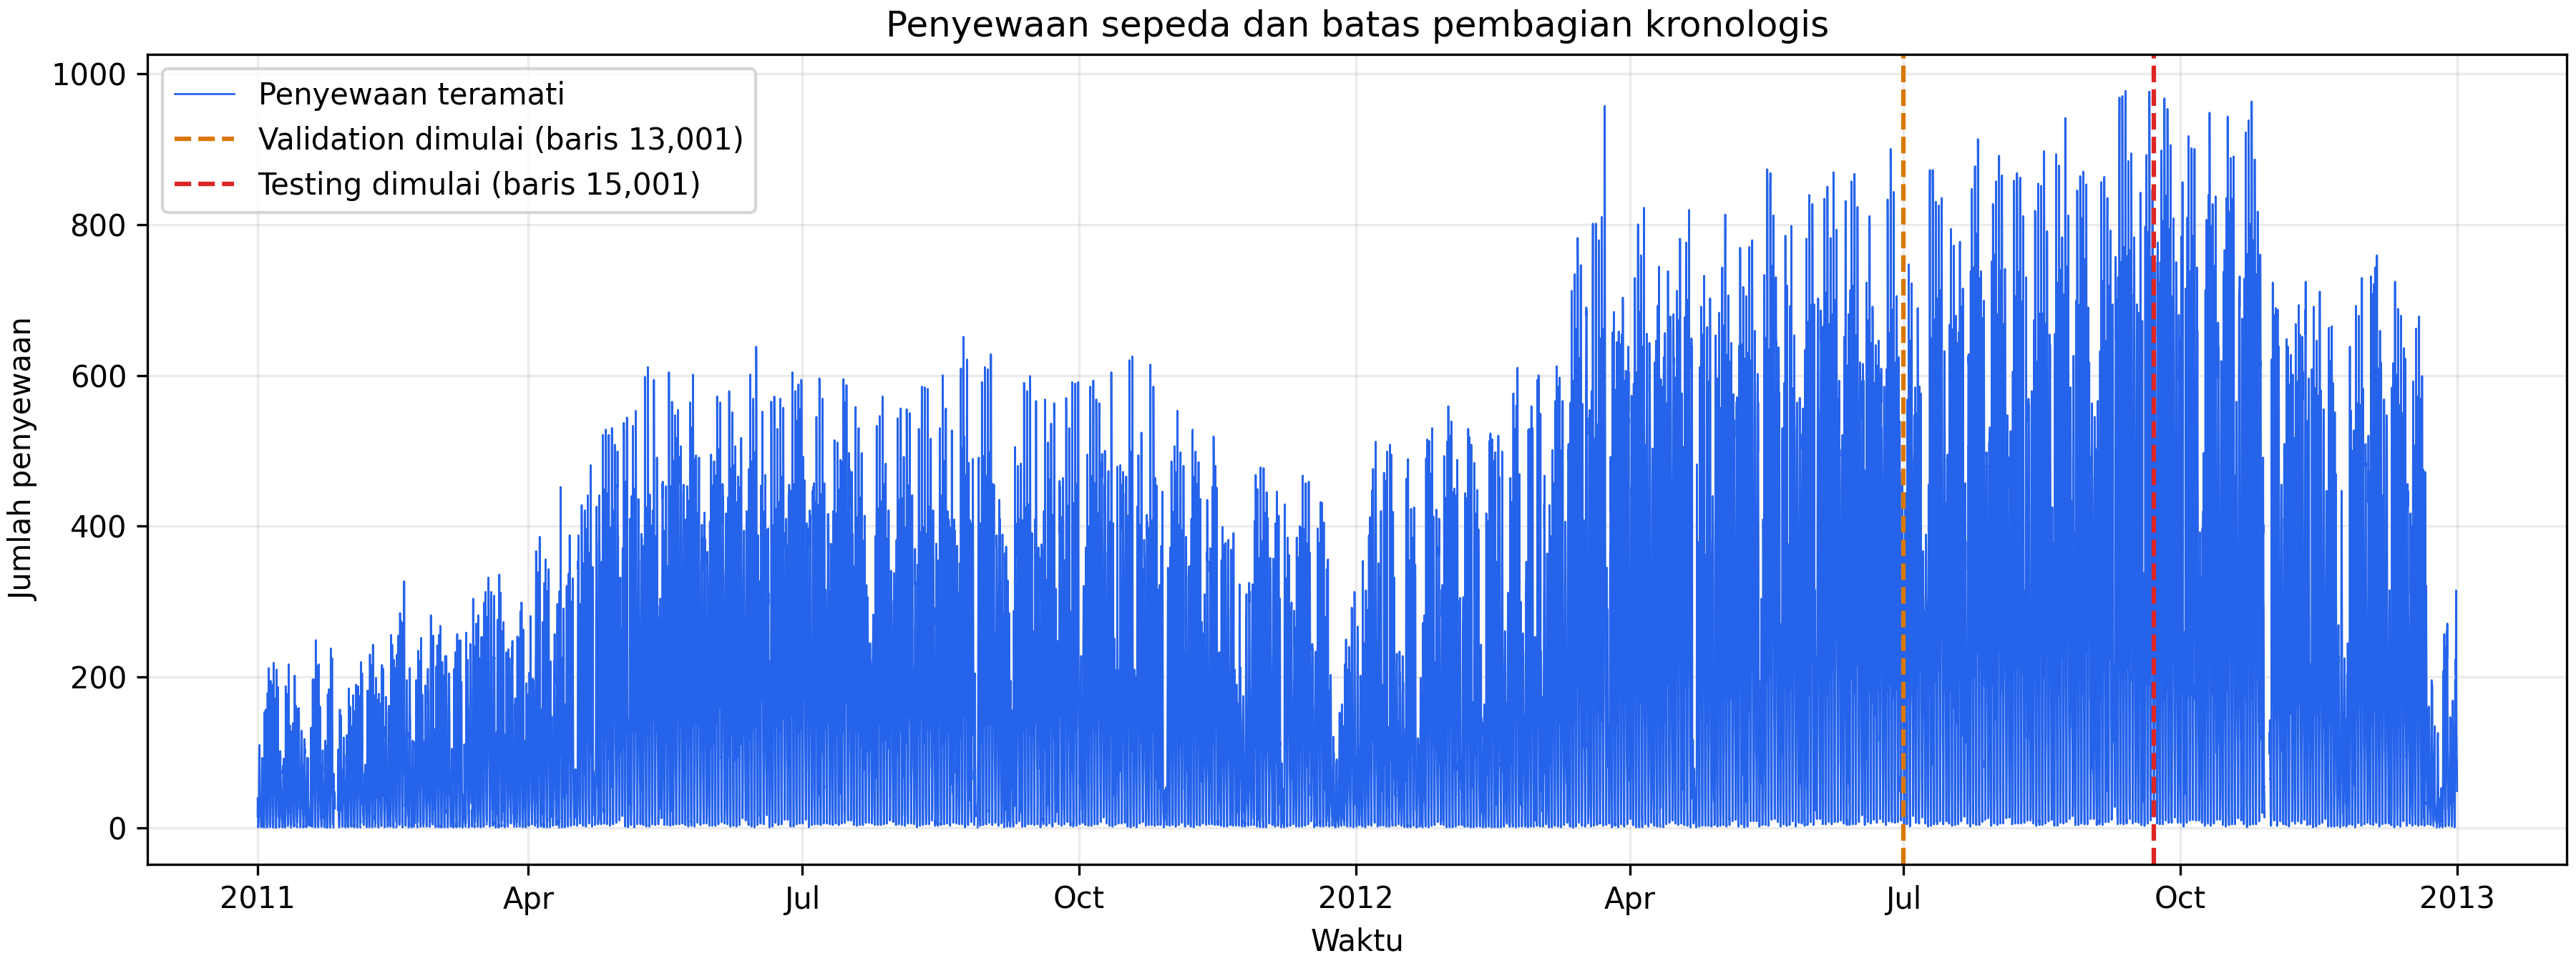

,Rerata penyewaan
Latih,167.71
Validasi,284.20
Uji,228.68


In [15]:
display(Image(filename=str(original_figure), width=1000))
display(split_means.rename(index={'training': 'Latih', 'validation': 'Validasi', 'testing': 'Uji'}).round(2).to_frame())

In [16]:
show_insight(f"Rerata penyewaan per jam adalah **{split_means['training']:.1f}** pada data latih, **{split_means['validation']:.1f}** pada validasi, dan **{split_means['testing']:.1f}** pada uji. Tingkat permintaan antarperiode berbeda, sehingga kemampuan menerapkan pola ke waktu berikutnya perlu diuji secara kronologis. Celah garis menandai jam tanpa pengamatan; grafik ini sendiri tidak menentukan penyebab perubahan permintaan.")

**Interpretasi**

Rerata penyewaan per jam adalah **167.7** pada data latih, **284.2** pada validasi, dan **228.7** pada uji. Tingkat permintaan antarperiode berbeda, sehingga kemampuan menerapkan pola ke waktu berikutnya perlu diuji secara kronologis. Celah garis menandai jam tanpa pengamatan; grafik ini sendiri tidak menentukan penyebab perubahan permintaan.

## 8. Grafik 2 — Loss pelatihan dan validasi

**Penjelasan sebelum kode.** Memeriksa proses belajar dan menunjukkan epoch yang dipilih berdasarkan nilai validasi terendah.

In [17]:
loss_figure = figures["training_loss"]
best_epoch = metadata["best_validation_epoch"]

**Penjelasan kode.** Grafik `training_loss` telah dibuat oleh fungsi `losses`
di dalam salinan `generate_visualizations`. Kurva memakai riwayat pelatihan dan
validasi yang sama dengan berkas model; penanda epoch terbaik berasal dari
metadata. MSE pada gambar memakai target terskala, sehingga berbeda satuan
dari MSE pengujian dalam jumlah penyewaan asli.

**Hasil.**

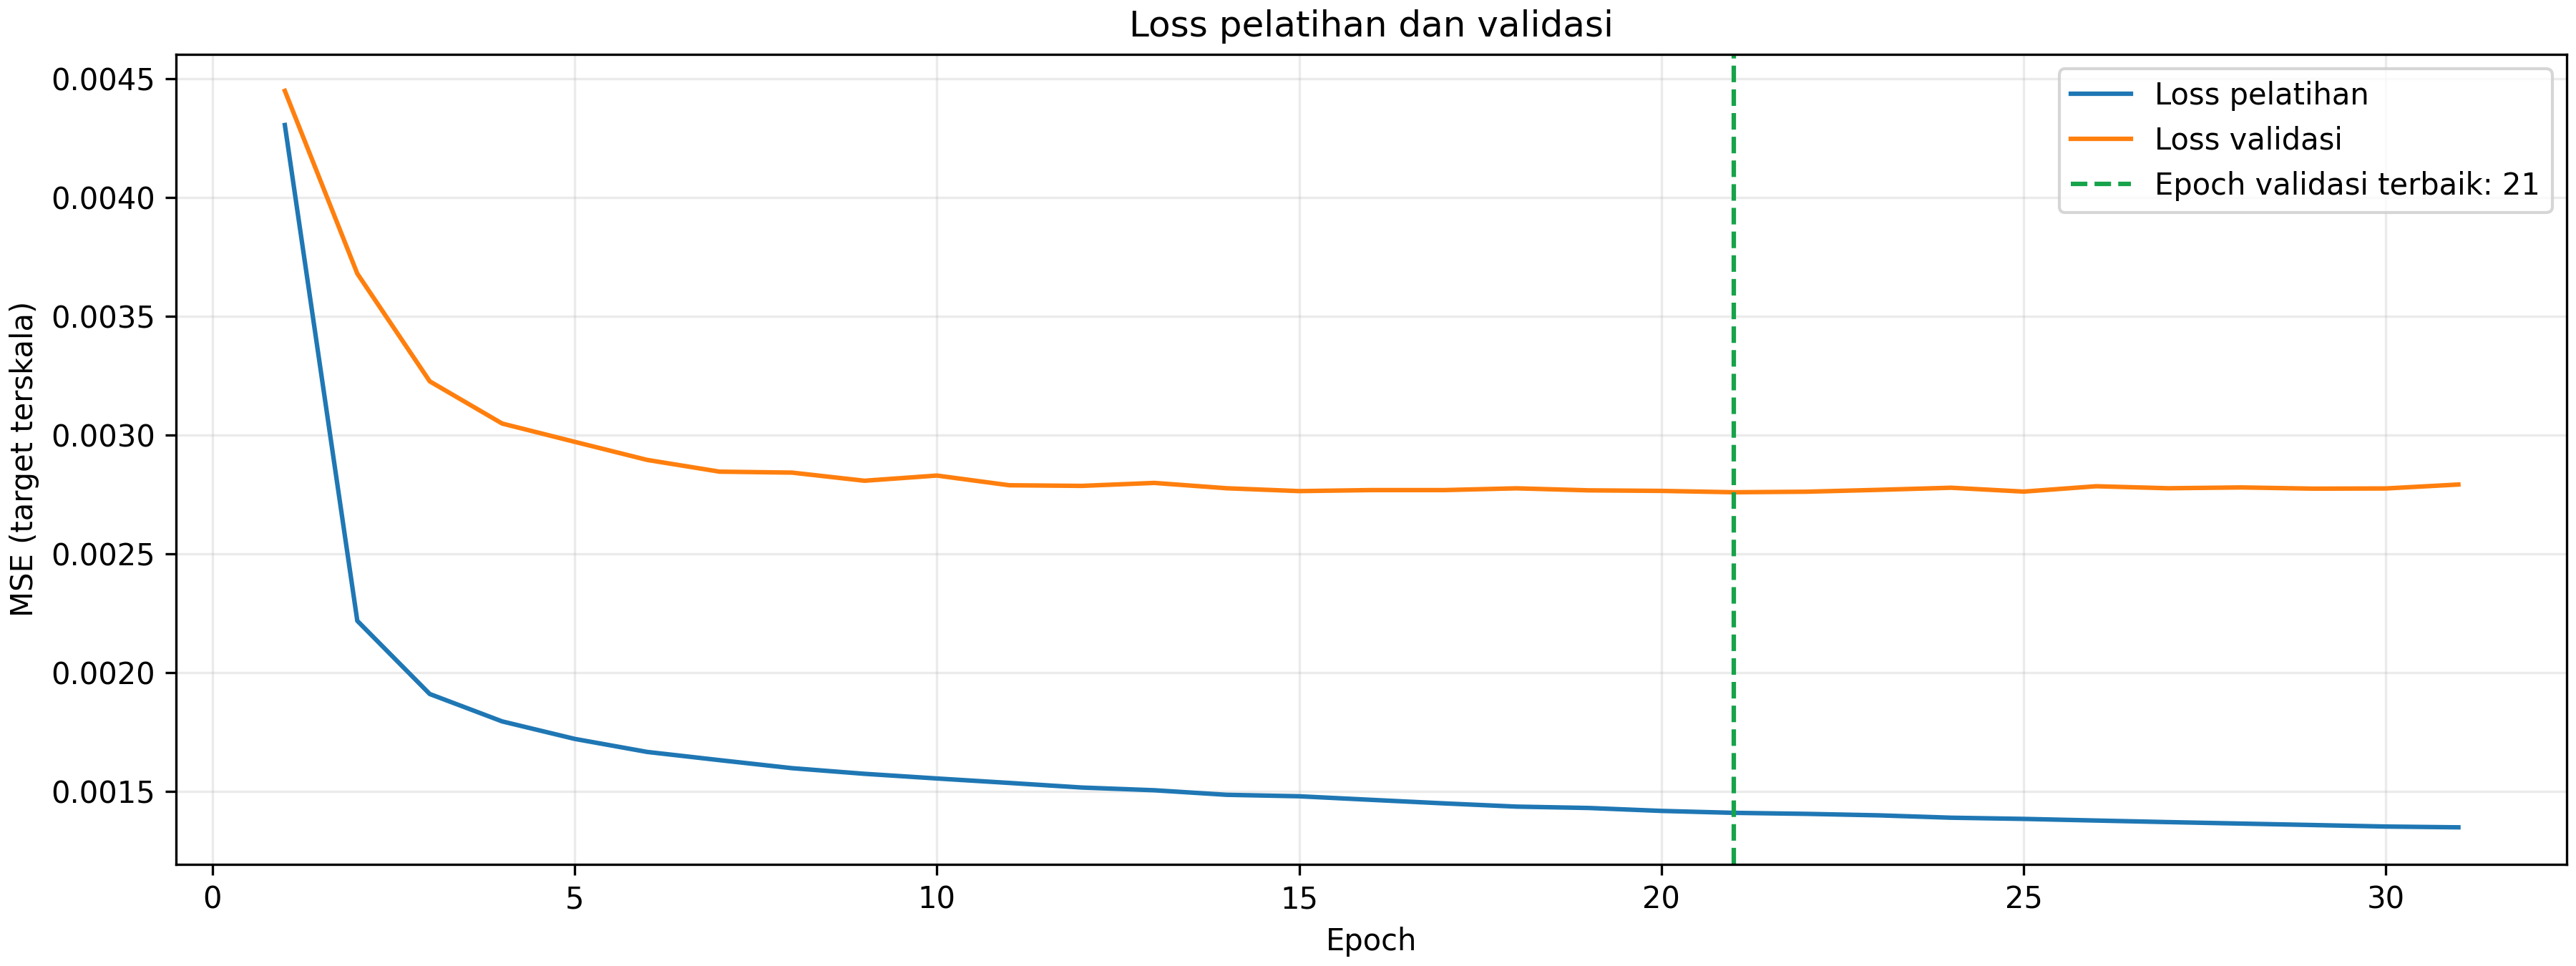

,epoch,loss,mae,val_loss,val_mae
20,21,0.001411,0.025229,0.00276,0.035248


In [18]:
display(Image(filename=str(loss_figure), width=1000))
display(history_frame.iloc[[best_epoch - 1]].round(6))

In [19]:
stop_reason = 'Pelatihan berhenti setelah sepuluh epoch tanpa minimum validasi baru.' if metadata['early_stopping_triggered'] else 'Pelatihan mencapai batas epoch yang ditetapkan.'
show_insight(f"Model terpilih berasal dari **epoch {best_epoch}**, dengan MSE validasi **{metadata['best_validation_loss']:.6f}**. Sebanyak **{metadata['completed_epochs']} dari maksimum {MAX_EPOCHS} epoch** selesai. {stop_reason} Loss validasi pada epoch terakhir adalah **{history['val_loss'][-1]:.6f}**. Bobot yang disimpan mengikuti minimum validasi, bukan otomatis bobot epoch terakhir. Data uji tidak dipakai untuk menentukan epoch tersebut.")

**Interpretasi**

Model terpilih berasal dari **epoch 21**, dengan MSE validasi **0.002760**. Sebanyak **31 dari maksimum 50 epoch** selesai. Pelatihan berhenti setelah sepuluh epoch tanpa minimum validasi baru. Loss validasi pada epoch terakhir adalah **0.002793**. Bobot yang disimpan mengikuti minimum validasi, bukan otomatis bobot epoch terakhir. Data uji tidak dipakai untuk menentukan epoch tersebut.

## 9. Grafik 3 — Nilai aktual dan prediksi

**Penjelasan sebelum kode.** Membandingkan perkiraan CNN dengan pengamatan pada
seluruh periode uji, menggunakan visualisasi yang sama dengan aplikasi repo.

In [20]:
prediction_figure = figures["actual_vs_predicted"]

**Penjelasan kode.** Fungsi `comparison` di dalam salinan
`generate_visualizations` menggambar aktual dan prediksi pada timestamp uji.
Reindex per jam memutus garis ketika target hilang atau dikecualikan karena
celah. Tabel pembanding di bawah dihitung pada kumpulan target yang sama.
Grafik utama mengikuti repo tanpa penambahan panel perbesaran.

**Hasil.**

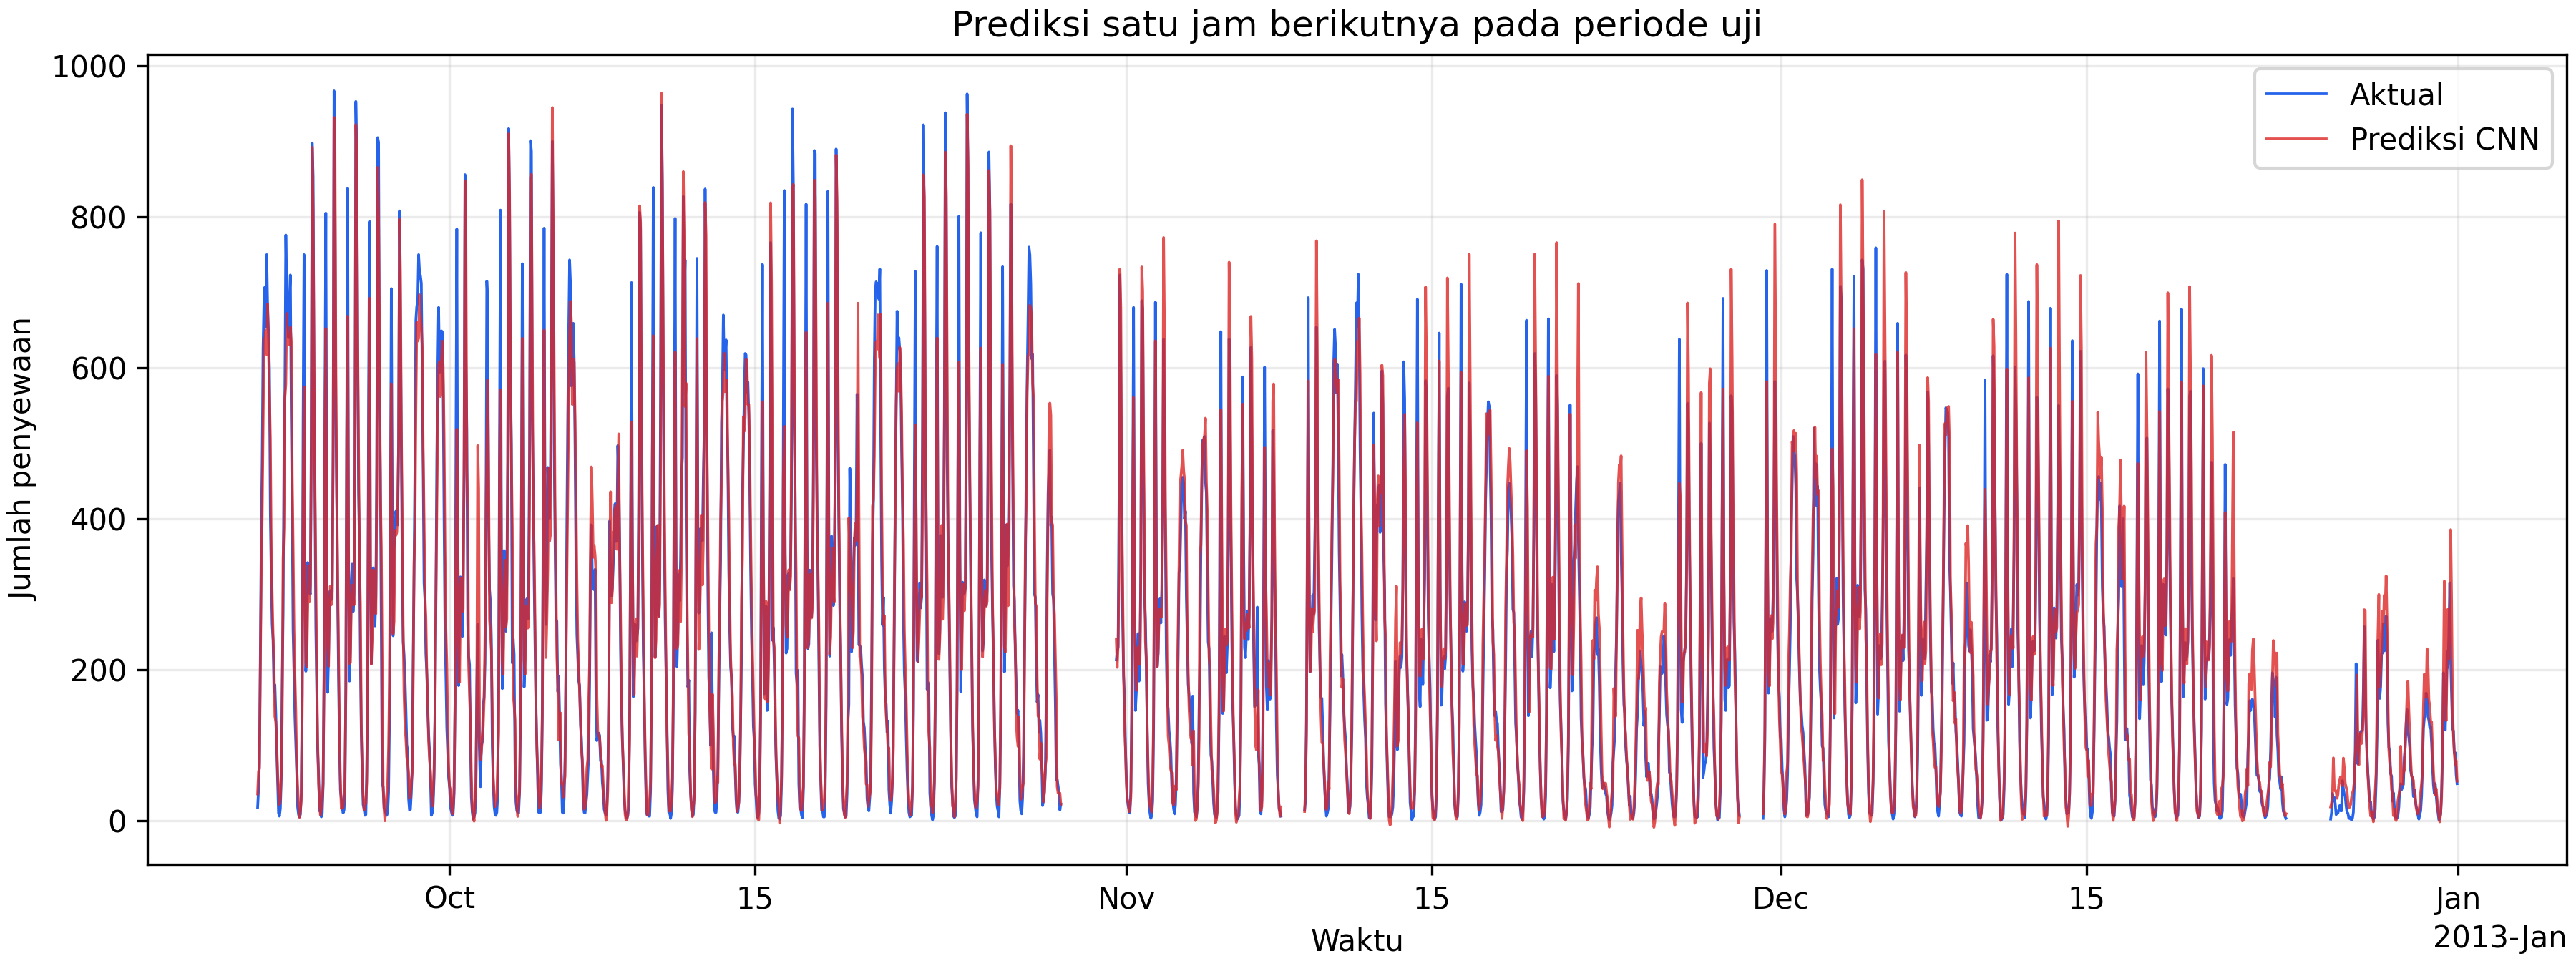

,Sampel,MAE,MSE,RMSE
Metode,,,,
CNN univariat,2261,35.1569,2843.2040,53.3217
Nilai satu jam sebelumnya,2261,80.1690,15283.1402,123.6250
Nilai 24 jam sebelumnya,2261,79.0279,17078.2795,130.6839


In [21]:
display(Image(filename=str(prediction_figure), width=1000))
display(comparison.round(4))

In [22]:
baseline_mae = comparison.loc["Nilai satu jam sebelumnya", "MAE"]
change = 100 * (baseline_mae - metrics["MAE"]) / baseline_mae
direction = "lebih rendah" if change >= 0 else "lebih tinggi"
show_insight(f"CNN menghasilkan **MAE {metrics['MAE']:.2f} penyewaan** dan "
             f"**RMSE {metrics['RMSE']:.2f} penyewaan** pada **{len(actual):,} target**. "
             f"MAE-nya **{abs(change):.1f}% {direction}** dibanding penggunaan nilai satu jam "
             "sebelumnya. RMSE memberi bobot lebih besar pada kesalahan besar; karena itu, "
             "garis yang sering berdekatan tetap dapat memiliki beberapa penyimpangan besar. "
             "Gunakan tabel pembanding untuk menilai manfaat CNN pada periode yang sama.")

**Interpretasi**

CNN menghasilkan **MAE 35.16 penyewaan** dan **RMSE 53.32 penyewaan** pada **2,261 target**. MAE-nya **56.1% lebih rendah** dibanding penggunaan nilai satu jam sebelumnya. RMSE memberi bobot lebih besar pada kesalahan besar; karena itu, garis yang sering berdekatan tetap dapat memiliki beberapa penyimpangan besar. Gunakan tabel pembanding untuk menilai manfaat CNN pada periode yang sama.

## 10. Grafik 4 — Galat prediksi sepanjang waktu

**Penjelasan sebelum kode.** Menemukan kapan model memprediksi terlalu tinggi atau terlalu rendah dan menghubungkan pola tersebut dengan bias, penyebaran galat, serta kesalahan terbesar.

In [23]:
error_figure = figures["prediction_errors"]
largest_miss = predictions.iloc[int(np.argmax(absolute_errors))]

**Penjelasan kode.** Fungsi `errors` dari salinan visualisasi repo menggambar
`predicted - actual` dan garis referensi nol. Positif berarti prediksi terlalu
tinggi, negatif berarti terlalu rendah. Statistik di bawah memakai laporan
numerik dari `save_numerical_results`; simpangan baku memakai ddof=0 terhadap
rerata galat.

**Hasil.**

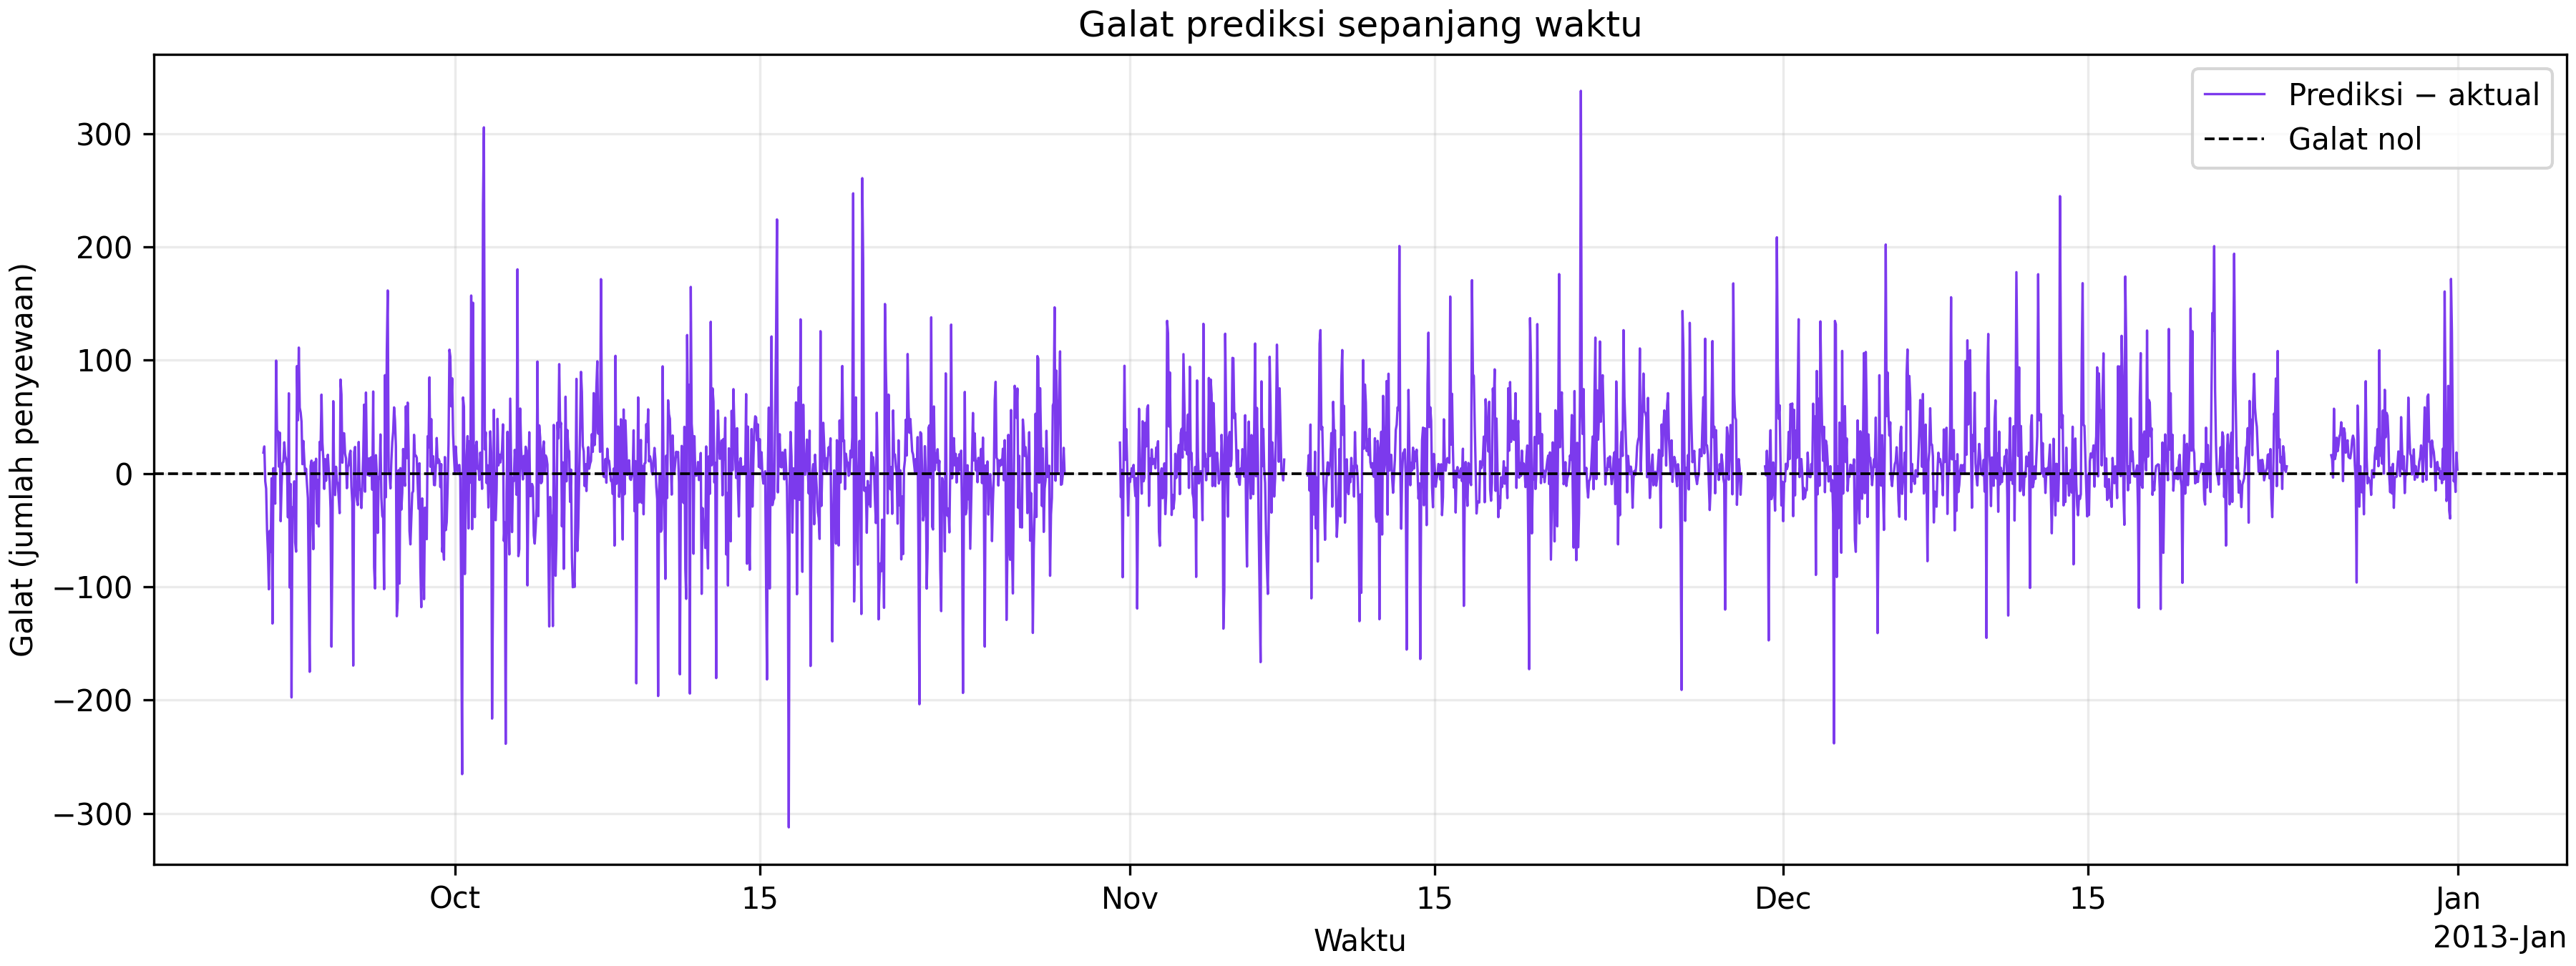

,Nilai
Bias (penyewaan),8.334045
Simpangan baku (penyewaan),52.666381
Varians (penyewaan kuadrat),2773.747720


In [24]:
display(Image(filename=str(error_figure), width=1000))
display(pd.Series({'Bias (penyewaan)': statistics['mean_error_bias'], 'Simpangan baku (penyewaan)': statistics['error_std'], 'Varians (penyewaan kuadrat)': statistics['error_variance']}, name='Nilai').to_frame())

In [25]:
tendency = 'terlalu tinggi' if statistics['mean_error_bias'] > 0 else 'terlalu rendah'
negative_count = int((predictions.predicted < 0).sum())
show_insight(f"Rerata galat adalah **{statistics['mean_error_bias']:.2f} penyewaan**, sehingga prediksi cenderung **{tendency}** secara rata-rata. Simpangan bakunya **{statistics['error_std']:.2f} penyewaan**. Kesalahan absolut terbesar adalah **{abs(largest_miss['error']):.2f}** pada **{largest_miss['timestamp']}**, dengan aktual **{largest_miss['actual']:.0f}** dan prediksi **{largest_miss['predicted']:.2f}**. Keluaran linier menghasilkan **{negative_count} prediksi negatif**; nilainya tetap disertakan dalam penghitungan metrik.")

**Interpretasi**

Rerata galat adalah **8.33 penyewaan**, sehingga prediksi cenderung **terlalu tinggi** secara rata-rata. Simpangan bakunya **52.67 penyewaan**. Kesalahan absolut terbesar adalah **337.66** pada **2012-11-21 17:00:00**, dengan aktual **374** dan prediksi **711.66**. Keluaran linier menghasilkan **19 prediksi negatif**; nilainya tetap disertakan dalam penghitungan metrik.

## 11. Grafik 5 — Distribusi galat

**Penjelasan sebelum kode.** Menggambarkan seberapa terpusat galat dan seberapa besar ekor kesalahan absolut, tanpa mengasumsikan distribusi normal.

In [26]:
(fig, ax) = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
ax.hist(errors, bins=50, color='#7c3aed', alpha=0.8, edgecolor='white', label='Galat uji')
ax.axvline(0, color='black', linestyle='--', label='Galat nol')
ax.axvline(statistics['mean_error_bias'], color='#d97706', label='Rerata galat')
ax.axvline(statistics['error_median'], color='#16a34a', linestyle=':', label='Median galat')
ax.set(title='Distribusi galat prediksi', xlabel='Prediksi − aktual (penyewaan)', ylabel='Jumlah target')
ax.grid(axis='y', alpha=0.25)
ax.legend()
distribution_figure = save_figure(fig, 'error_distribution')

**Penjelasan kode.** Histogram mengelompokkan galat bertanda. Rerata dan median menunjukkan pusat dengan cara berbeda. Persentil galat absolut menjelaskan besarnya kesalahan pada bagian tertentu dari distribusi empiris; persentil dihitung dengan interpolasi linier.

**Hasil.**

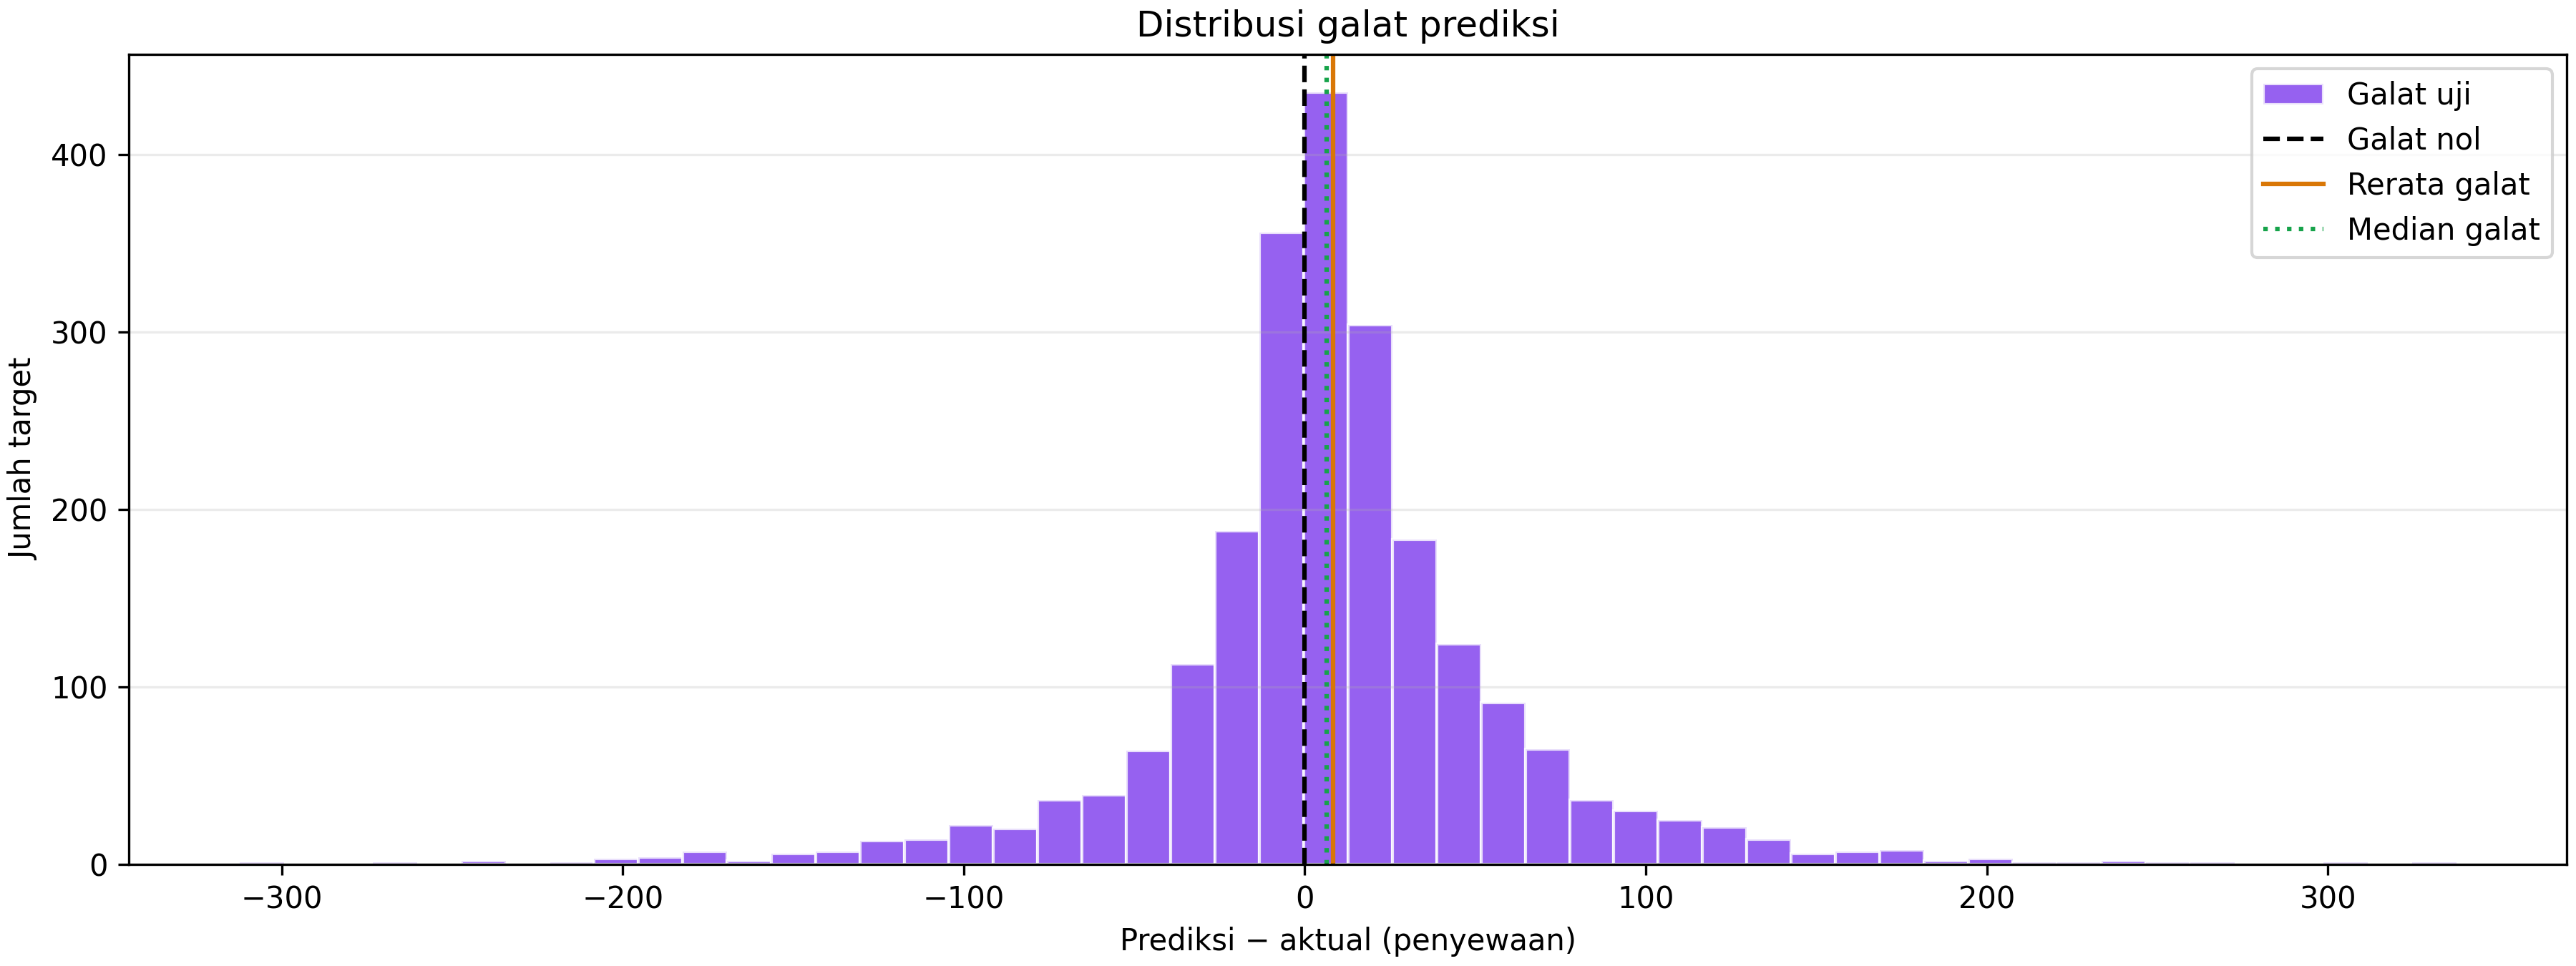

,Penyewaan
Median galat absolut,20.815357
Persentil 90,86.666950
Persentil 95,117.488093
Persentil 99,188.717787
Maksimum,337.656303


In [27]:
display(Image(filename=str(distribution_figure), width=1000))
display(pd.Series({'Median galat absolut': statistics['absolute_error_median'], 'Persentil 90': statistics['absolute_error_p90'], 'Persentil 95': statistics['absolute_error_p95'], 'Persentil 99': statistics['absolute_error_p99'], 'Maksimum': statistics['absolute_error_max']}, name='Penyewaan').to_frame())

In [28]:
over_percent = 100 * statistics['overprediction_count'] / len(actual)
under_percent = 100 * statistics['underprediction_count'] / len(actual)
show_insight(f"Median kesalahan absolut adalah **{statistics['absolute_error_median']:.2f}**, persentil ke-95 **{statistics['absolute_error_p95']:.2f}**, dan maksimum **{statistics['absolute_error_max']:.2f} penyewaan**. Nilai-nilai ini membedakan kesalahan lazim dan bagian ekornya. Sebanyak **{over_percent:.1f}%** target diprediksi terlalu tinggi dan **{under_percent:.1f}%** terlalu rendah. Besar kesalahan di masing-masing sisi juga memengaruhi bias, bukan hanya jumlah kejadiannya. Bentuk histogram belum merupakan uji kenormalan.")

**Interpretasi**

Median kesalahan absolut adalah **20.82**, persentil ke-95 **117.49**, dan maksimum **337.66 penyewaan**. Nilai-nilai ini membedakan kesalahan lazim dan bagian ekornya. Sebanyak **59.6%** target diprediksi terlalu tinggi dan **40.4%** terlalu rendah. Besar kesalahan di masing-masing sisi juga memengaruhi bias, bukan hanya jumlah kejadiannya. Bentuk histogram belum merupakan uji kenormalan.

## 12. Grafik 6 — Galat menurut jam dalam sehari

**Penjelasan sebelum kode.** Memeriksa apakah besar kesalahan dan arahnya berubah sepanjang siklus harian, dengan memperhatikan jumlah pengamatan yang tersedia untuk setiap jam.

In [29]:
(fig, axes) = plt.subplots(2, 1, figsize=(12, 6.5), constrained_layout=True, sharex=True)
axes[0].bar(hourly.hour_of_day, hourly.MAE, color='#2563eb', label='MAE')
axes[0].set(title='Kesalahan absolut menurut jam', ylabel='MAE (penyewaan)')
colors = np.where(hourly.mean_error_bias >= 0, '#d97706', '#7c3aed')
axes[1].bar(hourly.hour_of_day, hourly.mean_error_bias, color=colors)
axes[1].axhline(0, color='black', linewidth=0.9)
axes[1].set(title='Bias menurut jam: oranye terlalu tinggi, ungu terlalu rendah', xlabel='Jam dalam sehari', ylabel='Bias (penyewaan)')
axes[1].set_xticks(range(24))
for ax in axes:
    ax.grid(axis='y', alpha=0.25)
axes[0].legend()
hourly_figure = save_figure(fig, 'hour_of_day_errors')
worst_hour = hourly.loc[hourly.MAE.idxmax()]
best_hour = hourly.loc[hourly.MAE.idxmin()]

**Penjelasan kode.** Setiap batang menggabungkan semua target layak pada jam yang sama di berbagai tanggal. Panel atas memakai MAE untuk besar kesalahan dan panel bawah mempertahankan tandanya. Jumlah sampel dapat berbeda akibat celah; tidak ada jam kosong yang diperlakukan sebagai kesalahan nol. Rerata aktual membantu membandingkan volume penyewaan antarjam.

**Hasil.**

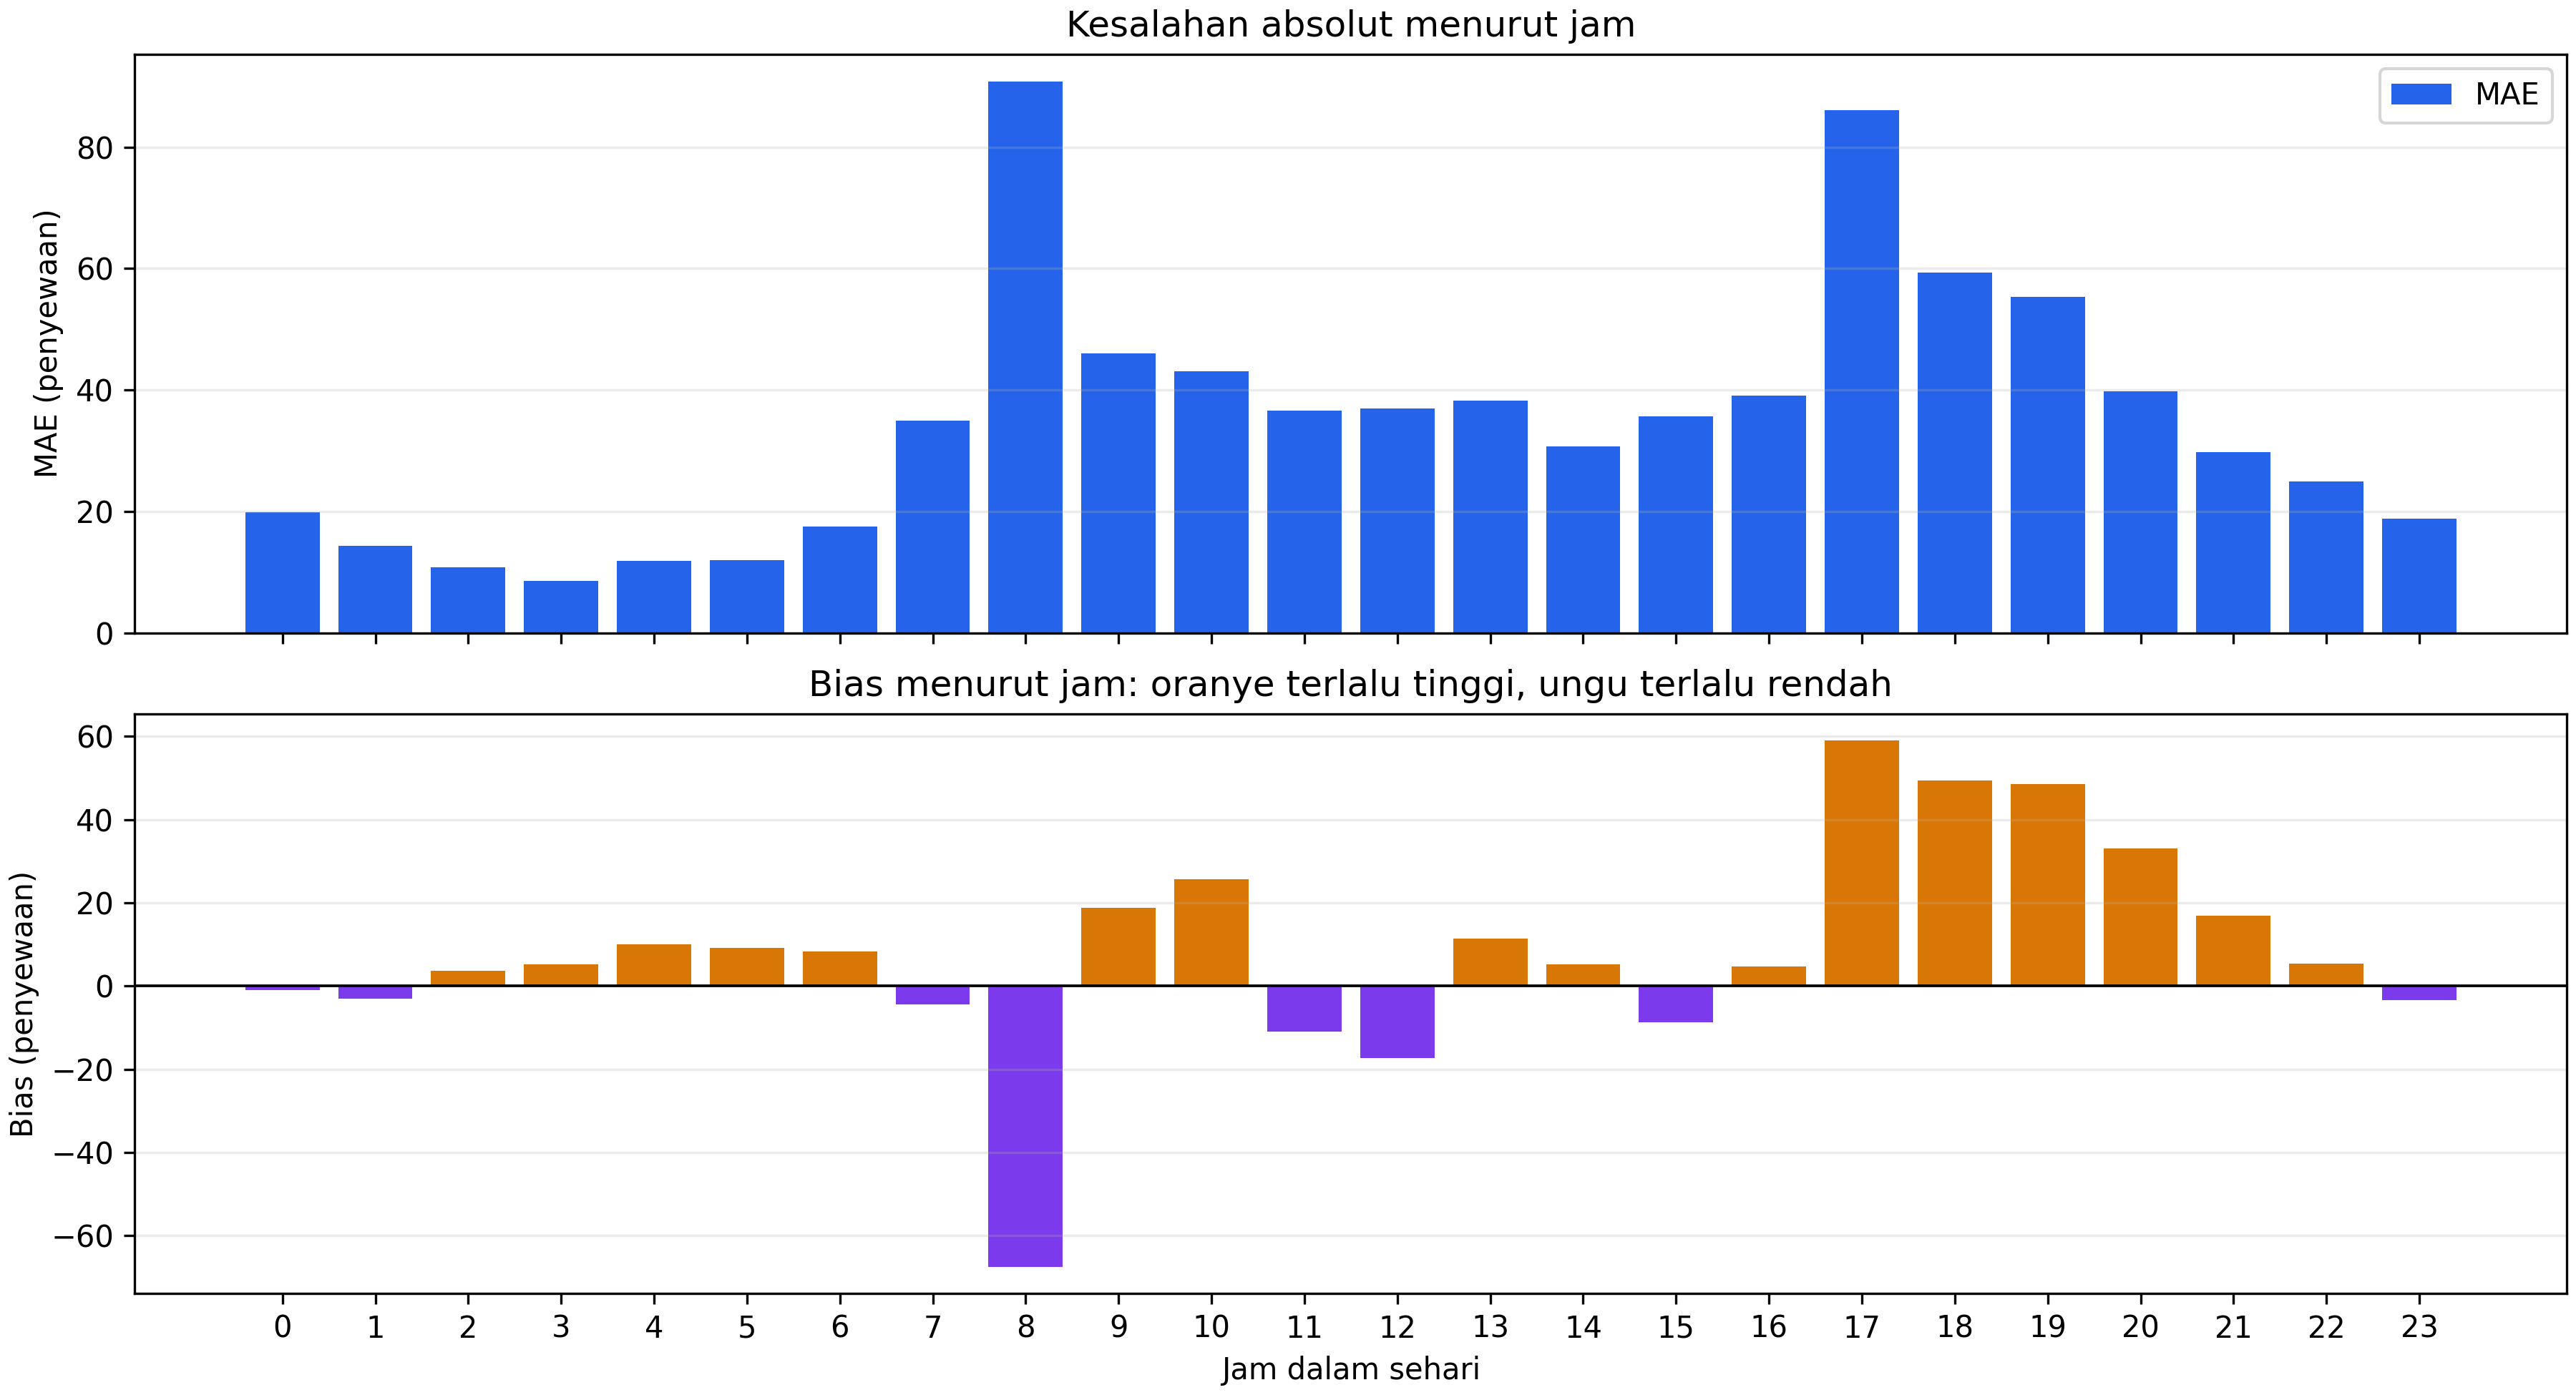

,Jam,Sampel,Rerata aktual,MAE,Bias,Simpangan baku
0,0,94,64.351,19.830,-0.922,33.497
1,1,93,42.290,14.361,-3.074,20.156
2,2,93,26.763,10.818,3.709,17.009
3,3,91,12.923,8.589,5.222,11.865
4,4,93,8.226,11.931,10.073,11.395
5,5,94,26.468,11.952,9.213,12.560
6,6,94,91.947,17.571,8.381,20.610
7,7,94,261.745,34.940,-4.387,53.561
8,8,94,462.894,90.797,-67.517,94.114
9,9,94,281.383,46.012,18.848,58.293


In [30]:
display(Image(filename=str(hourly_figure), width=1000))
display(hourly[['hour_of_day', 'samples', 'actual_mean', 'MAE', 'mean_error_bias', 'error_std']].rename(columns={'hour_of_day': 'Jam', 'samples': 'Sampel', 'actual_mean': 'Rerata aktual', 'mean_error_bias': 'Bias', 'error_std': 'Simpangan baku'}).round(3))

In [31]:
show_insight(f"MAE terbesar terjadi pada **{int(worst_hour['hour_of_day']):02d}:00**, sebesar **{worst_hour['MAE']:.2f} penyewaan** dari **{int(worst_hour['samples'])} target**. MAE terkecil terjadi pada **{int(best_hour['hour_of_day']):02d}:00**, sebesar **{best_hour['MAE']:.2f}**. Jumlah sampel per jam berada antara **{hourly.samples.min()} dan {hourly.samples.max()}**. Kesalahan absolut yang lebih besar perlu dibaca bersama volume aktual. Temuan ini merupakan diagnosis atas pengujian yang sudah selesai; perubahan model sebaiknya dipilih dengan validasi dan dinilai pada periode uji baru.")

**Interpretasi**

MAE terbesar terjadi pada **08:00**, sebesar **90.80 penyewaan** dari **94 target**. MAE terkecil terjadi pada **03:00**, sebesar **8.59**. Jumlah sampel per jam berada antara **91 dan 95**. Kesalahan absolut yang lebih besar perlu dibaca bersama volume aktual. Temuan ini merupakan diagnosis atas pengujian yang sudah selesai; perubahan model sebaiknya dipilih dengan validasi dan dinilai pada periode uji baru.

## 13. Memverifikasi penyimpanan dan merangkum eksperimen

**Penjelasan sebelum kode.** Membuktikan bahwa model dan scaler yang disimpan dapat menghasilkan prediksi yang sama, serta memastikan data mentah dan berkas keluaran tersedia.

In [32]:
saved_paths = artifact_paths(MODEL_NAME)
saved_hashes = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in saved_paths.items()}
restored = load_bundle(MODEL_NAME)
restored_data = prepare_data(DATASET_PATH, MODE, WINDOW_SIZE,
    feature_scaler=restored.feature_scaler, target_scaler=restored.target_scaler,
    saved_metadata=restored.metadata, report=lambda message: None)
np.testing.assert_array_equal(restored_data.test.X, data.test.X)
restored_scaled = np.concatenate([
    np.asarray(restored.model(restored_data.test.X[start:start + BATCH_SIZE], training=False))
    for start in range(0, len(restored_data.test.y), BATCH_SIZE)
])
restored_counts = restored.target_scaler.inverse_transform(restored_scaled.astype(np.float64)).ravel()
np.testing.assert_allclose(restored_counts, predictions.predicted, rtol=0, atol=1e-6)
assert original_dataset_hash == hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
assert saved_hashes == {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in saved_paths.items()}
figure_paths = [original_figure, loss_figure, prediction_figure, error_figure,
                distribution_figure, hourly_figure]
all_paths = [*saved_paths.values(), *preprocessing_paths.values(), evaluation.predictions_path,
             evaluation.metrics_path, *evaluation.numerical_paths.values(), baseline_path, *figure_paths]
assert all(path.is_file() for path in all_paths)
assert plt.get_fignums() == []
verification = {"model_name": MODEL_NAME, "evaluation_run": evaluation.run_id,
    "max_epochs": MAX_EPOCHS, "completed_epochs": metadata["completed_epochs"],
    "best_validation_epoch": best_epoch, "test_samples": len(actual),
    "MAE": metrics["MAE"], "MSE": metrics["MSE"], "RMSE": metrics["RMSE"],
    "figures": len(figure_paths), "numerical_reports": len(evaluation.numerical_paths) + 1,
    "saved_predictions_reproduced": True, "dataset_unchanged": True}
artifact_table = pd.DataFrame({"Berkas hasil": [str(path.relative_to(PROJECT_ROOT)) for path in all_paths]})

**Penjelasan kode.** `artifact_paths`, `load_bundle`, dan `prepare_data` memakai
definisi salinan repo di sel-sel sebelumnya. Model, metadata, scaler, dan batas
data dipakai kembali tanpa pelatihan atau fitting scaler baru. Prediksi harus
cocok dalam toleransi 0,000001 penyewaan. Pemeriksaan hash memastikan data asli
dan bundle model tetap utuh. Semua lokasi hasil ditampilkan relatif terhadap
folder kerja notebook.

**Hasil.**

In [33]:
display(artifact_table)
display(JSON(verification))

,Berkas hasil
0,output/model/uni_model_notebook_repo/uni_model...
1,output/model/uni_model_notebook_repo/uni_model...
2,output/model/uni_model_notebook_repo/uni_model...
3,output/model/uni_model_notebook_repo/uni_model...
4,output/model/uni_model_notebook_repo/uni_model...
5,output/pre_result/uni_model_notebook_repo/uni_...
6,output/pre_result/uni_model_notebook_repo/uni_...
7,output/pre_result/uni_model_notebook_repo/uni_...
8,output/pre_result/uni_model_notebook_repo/uni_...
9,output/test_output/uni_model_notebook_repo/uni...


<IPython.core.display.JSON object>

## Kesimpulan dan batas interpretasi

Fungsi inti notebook mengikuti kode repo, sedangkan penjelasan serta
interpretasi hasil disusun dalam bahasa Indonesia. Kemandirian notebook
diperoleh dengan menyalin definisi fungsi ke sel, bukan dengan mengimpor
modul proyek. Perubahan pada lokasi data/output dan teks gambar tidak
mengubah algoritme pemrosesan, arsitektur, atau aturan evaluasinya.

Baca MAE bersama RMSE, bias, simpangan baku, dan persentil galat absolut.
Model dievaluasi pada target satu jam berikutnya yang memiliki konteks
waktu utuh. Pengamatan uji sebelumnya yang sudah tersedia boleh menjadi
konteks berikutnya; hasil ini bukan prakiraan rekursif beberapa jam.

Histogram dan ringkasan per jam menjelaskan pengujian yang telah selesai.
Perubahan model berdasarkan temuan tersebut perlu dipilih lewat validasi
dan dinilai pada periode uji baru. Nilai hasil dapat sedikit berbeda
antarversi pustaka atau perangkat keras meskipun seed sama.